# 02 · Modelado, análisis cuantitativo y análisis cualitativo

Este notebook cubre los entregables **2 (15 %) Entrenamiento**, **3 (20 %) Análisis cuantitativo** y **4 (20 %) Análisis cualitativo**:

**Parte I · Entrenamiento y análisis cuantitativo**

1. División de los datos en entrenamiento, validación y prueba.
2. Preprocesamiento dentro de un *pipeline* (sin fuga de datos).
3. Modelo de referencia (*baseline*).
4. Dos modelos con búsqueda de hiperparámetros por validación cruzada:
   - **Regresión logística regularizada** (L2, L1 o *elastic net*).
   - **Árbol de decisión**.
5. Métricas en entrenamiento y validación, comparación estadística y selección del modelo.
6. Evaluación final del modelo elegido en el conjunto de prueba.
7. Conclusiones del análisis cuantitativo.

**Parte II · Análisis cualitativo (interpretación)**

8. Comportamiento global de los modelos (coeficientes, reglas del árbol, permutación, SHAP, ICE/PDP).
9. Comportamiento local: explicación de clientes individuales (SHAP y LIME).
10. Síntesis.

**Entrada:** `data/processed/churn_clean.csv` (salida del notebook 01).
**Salida:** `data/processed/predicciones.csv` (probabilidades de ambos modelos, para el análisis de valor de negocio).

> **¿Por qué una regresión logística *regularizada*?** La regresión logística de scikit-learn minimiza la log-pérdida más una penalización sobre el tamaño de los coeficientes. El hiperparámetro **`C` es el inverso de la fuerza de regularización** (C = 1/λ): un `C` pequeño encoge más los coeficientes. **`l1_ratio`** elige el tipo de penalización: 0 = **L2 (Ridge)**, que encoge todos los coeficientes; 1 = **L1 (Lasso)**, que puede llevar coeficientes a cero y hace selección de variables; valores intermedios = ***elastic net***. La regularización reduce el sobreajuste y estabiliza los coeficientes cuando hay variables correlacionadas (por ejemplo `age` y `age_sq`).

In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
pd.set_option("display.max_columns", 50)

plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.3, "axes.titleweight": "bold", "font.size": 10,
})
C_NO, C_SI = "#2a78d6", "#eb6834"          # no abandona / abandona
C_LR, C_DT = "#2a78d6", "#eb6834"          # regresión logística / árbol
C_GRIS = "#8a8984"
PAL_CHURN = {0: C_NO, 1: C_SI}

DATA_DIR = Path("../data")
PROC_DIR = DATA_DIR / "processed"
FIG_DIR = Path("../reports/figures")
for d in (PROC_DIR, FIG_DIR):
    d.mkdir(parents=True, exist_ok=True)
SEED = 42

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             average_precision_score, confusion_matrix, ConfusionMatrixDisplay,
                             precision_recall_curve, roc_curve)
from statsmodels.stats.contingency_tables import mcnemar

import shap
from lime.lime_tabular import LimeTabularExplainer
from sklearn.inspection import permutation_importance, PartialDependenceDisplay
from sklearn.tree import plot_tree, export_text

### Variables del modelo

Variables seleccionadas en el notebook 01 (se descartaron `tenure`, `estimated_salary` y `credit_card`), agrupadas según el tratamiento que reciben en el preprocesamiento.

In [2]:
TARGET = "churn"
NUMERICAS = ["credit_score", "balance"]
EDAD = ["age"]
CATEGORICAS = ["country", "gender", "products_number"]
BINARIAS = ["active_member"]
FEATURES = NUMERICAS + EDAD + CATEGORICAS + BINARIAS
FEATURES

['credit_score',
 'balance',
 'age',
 'country',
 'gender',
 'products_number',
 'active_member']

---
# Parte I · Entrenamiento y análisis cuantitativo

## 1. División de los datos

Se usa una división **60 / 20 / 20 estratificada** por `churn`, con semilla fija (`random_state=42`):

| Conjunto | Uso |
|---|---|
| **Entrenamiento (60 %)** | Ajustar el preprocesamiento (medianas, escalado) y los modelos. Sobre él se hace la **validación cruzada estratificada de 5 *folds*** para elegir hiperparámetros. |
| **Validación (20 %)** | Comparar los dos modelos ya ajustados y elegir el modelo final y el umbral de decisión. |
| **Prueba (20 %)** | Usado **una sola vez**, al final, para estimar el desempeño esperado en producción. |

Estratificar mantiene la proporción de abandono (~20 %) igual en los tres conjuntos, lo que es necesario con clases desbalanceadas.

In [3]:
df = pd.read_csv(PROC_DIR / "churn_clean.csv")
X, y = df[FEATURES], df[TARGET]

X_train, X_tmp, y_train, y_tmp = train_test_split(X, y, test_size=0.4, stratify=y, random_state=SEED)
X_val, X_test, y_val, y_test = train_test_split(X_tmp, y_tmp, test_size=0.5, stratify=y_tmp, random_state=SEED)

resumen = pd.DataFrame({
    "registros": [len(y_train), len(y_val), len(y_test)],
    "% del total": [len(y_train) / len(y), len(y_val) / len(y), len(y_test) / len(y)],
    "abandonos": [y_train.sum(), y_val.sum(), y_test.sum()],
    "tasa de abandono": [y_train.mean(), y_val.mean(), y_test.mean()],
}, index=["entrenamiento", "validación", "prueba"])
display(resumen)

print("Variables de entrada:", FEATURES)

,registros,% del total,abandonos,tasa de abandono
entrenamiento,6000,0.6000,1222,0.2037
validación,2000,0.2000,408,0.2040
prueba,2000,0.2000,407,0.2035


Variables de entrada: ['credit_score', 'balance', 'age', 'country', 'gender', 'products_number', 'active_member']


## 2. Preprocesamiento

El preprocesamiento se define en la función `make_preprocessor` y va **dentro del pipeline**. Así, en cada *fold* de la validación cruzada las medianas y el escalado se calculan solo con los datos de entrenamiento de ese *fold*.

| Paso | Regresión logística | Árbol de decisión |
|---|---|---|
| Nulos (`credit_score`, `age`, `balance`) | Mediana del entrenamiento | Mediana del entrenamiento |
| `age` | `age` + **`age_sq`** (variable derivada) | `age` (el árbol capta la no linealidad solo) |
| Escalado | `StandardScaler` (necesario para que la penalización trate igual a todos los coeficientes) | No se escala (los árboles no lo necesitan y así los umbrales se leen en unidades reales) |
| Categóricas | One-hot con categoría de referencia (France, Female, 1 producto) | Igual |

In [4]:
def edad_y_cuadrado(X):
    """Devuelve [edad, edad²] para capturar la relación en U invertida edad–abandono."""
    X = np.asarray(X, dtype=float)
    return np.hstack([X, X ** 2])


def make_preprocessor(lineal, edad_cuadrado=True, productos_categorica=True):
    """lineal=True  -> regresión logística: imputa con la mediana, añade age_sq y estandariza.
    lineal=False -> árbol: solo imputa (los umbrales del árbol quedan en unidades originales).
    Las categóricas van con one-hot (referencia = France, Female, 1 producto).
    `edad_cuadrado` y `productos_categorica` solo se cambian en la ablación (sección 5.4)."""
    imputar = ("imputar", SimpleImputer(strategy="median"))
    numericas = NUMERICAS + ([] if productos_categorica else ["products_number"])
    categoricas = [c for c in CATEGORICAS if productos_categorica or c != "products_number"]
    if lineal:
        num = Pipeline([imputar, ("escalar", StandardScaler())])
        pasos_edad = [imputar]
        if edad_cuadrado:
            pasos_edad.append(("cuadrado", FunctionTransformer(
                edad_y_cuadrado, feature_names_out=lambda t, f: np.array(["age", "age_sq"], dtype=object))))
        edad = Pipeline(pasos_edad + [("escalar", StandardScaler())])
    else:
        num = Pipeline([imputar])
        edad = Pipeline([imputar])
    return ColumnTransformer(
        [("num", num, numericas),
         ("edad", edad, EDAD),
         ("cat", OneHotEncoder(drop="first", handle_unknown="ignore", sparse_output=False), categoricas),
         ("bin", "passthrough", BINARIAS)],
        verbose_feature_names_out=False,
    )

In [5]:
pd.DataFrame({
    "regresión logística": pd.Series(make_preprocessor(lineal=True).fit(X_train).get_feature_names_out()),
    "árbol de decisión": pd.Series(make_preprocessor(lineal=False).fit(X_train).get_feature_names_out()),
}).fillna("")

,regresión logística,árbol de decisión
0,credit_score,credit_score
1,balance,balance
2,age,age
3,age_sq,country_Germany
4,country_Germany,country_Spain
5,country_Spain,gender_Male
6,gender_Male,products_number_2
7,products_number_2,products_number_3
8,products_number_3,products_number_4
9,products_number_4,active_member


## 3. Modelo de referencia (*baseline*)

Un modelo que siempre predice la clase mayoritaria ("no abandona") sirve de piso: cualquier modelo útil debe superarlo en las métricas de la clase positiva.

In [6]:
dummy = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
print(f"Accuracy del baseline en validación: {accuracy_score(y_val, dummy.predict(X_val)):.3f}  (recall = 0: no detecta ningún abandono)")

Accuracy del baseline en validación: 0.796  (recall = 0: no detecta ningún abandono)


## 4. Búsqueda de hiperparámetros

Para ambos modelos se usa `GridSearchCV` con **validación cruzada estratificada de 5 *folds*** sobre el entrenamiento. La métrica de selección es **F1**, como en la guía del curso: con clases desbalanceadas, F1 equilibra la precisión (no molestar a clientes que no se iban a ir) y el recall (no dejar escapar a quienes sí se van). También se registran AUC-ROC y AP. El umbral óptimo de negocio se calcula aparte, en el análisis de valor de negocio.

### 4.1 Regresión logística regularizada

| Hiperparámetro | Valores | Significado |
|---|---|---|
| `C` | 0,001 · 0,01 · 0,1 · 1 · 10 · 100 | Inverso de la fuerza de regularización |
| `l1_ratio` | 0 (L2) · 0,5 (*elastic net*) · 1 (L1) | Tipo de penalización |
| `class_weight` | None · balanced | `balanced` pondera más los errores en la clase minoritaria |

Se usa el *solver* `saga`, que admite las tres penalizaciones.

In [7]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
SCORING = {"f1": "f1", "roc_auc": "roc_auc", "ap": "average_precision"}

pipe_lr = Pipeline([("pre", make_preprocessor(lineal=True)),
                    ("modelo", LogisticRegression(solver="saga", max_iter=10000, random_state=SEED))])
grid_lr = {"modelo__C": [0.001, 0.01, 0.1, 1, 10, 100],
           "modelo__l1_ratio": [0.0, 0.5, 1.0],
           "modelo__class_weight": [None, "balanced"]}
gs_lr = GridSearchCV(pipe_lr, grid_lr, scoring=SCORING, refit="f1", cv=cv, n_jobs=-1, return_train_score=True)
gs_lr.fit(X_train, y_train)

def tabla_cv(gs, n=8):
    r = pd.DataFrame(gs.cv_results_)
    cols = [c for c in r.columns if c.startswith("param_")]
    t = r[cols + ["mean_train_f1", "mean_test_f1", "std_test_f1", "mean_test_roc_auc", "mean_test_ap", "rank_test_f1"]]
    t.columns = [c.replace("param_modelo__", "") for c in t.columns]
    return t.sort_values("rank_test_f1").head(n)

print("Mejores hiperparámetros:", gs_lr.best_params_, f"| F1 CV = {gs_lr.best_score_:.3f}")
tabla_cv(gs_lr)

Mejores hiperparámetros: {'modelo__C': 1, 'modelo__class_weight': 'balanced', 'modelo__l1_ratio': 0.0} | F1 CV = 0.558


,C,class_weight,l1_ratio,mean_train_f1,mean_test_f1,std_test_f1,mean_test_roc_auc,mean_test_ap,rank_test_f1
21,1.0000,balanced,0.0000,0.5607,0.5580,0.0114,0.8394,0.6520,1
22,1.0000,balanced,0.5000,0.5610,0.5577,0.0117,0.8396,0.6528,2
23,1.0000,balanced,1.0000,0.5610,0.5576,0.0120,0.8397,0.6537,3
29,10.0000,balanced,1.0000,0.5612,0.5575,0.0117,0.8398,0.6535,4
34,100.0000,balanced,0.5000,0.5613,0.5575,0.0117,0.8398,0.6536,4
35,100.0000,balanced,1.0000,0.5613,0.5575,0.0117,0.8398,0.6536,4
33,100.0000,balanced,0.0000,0.5614,0.5575,0.0117,0.8398,0.6535,4
28,10.0000,balanced,0.5000,0.5613,0.5571,0.0121,0.8398,0.6536,8


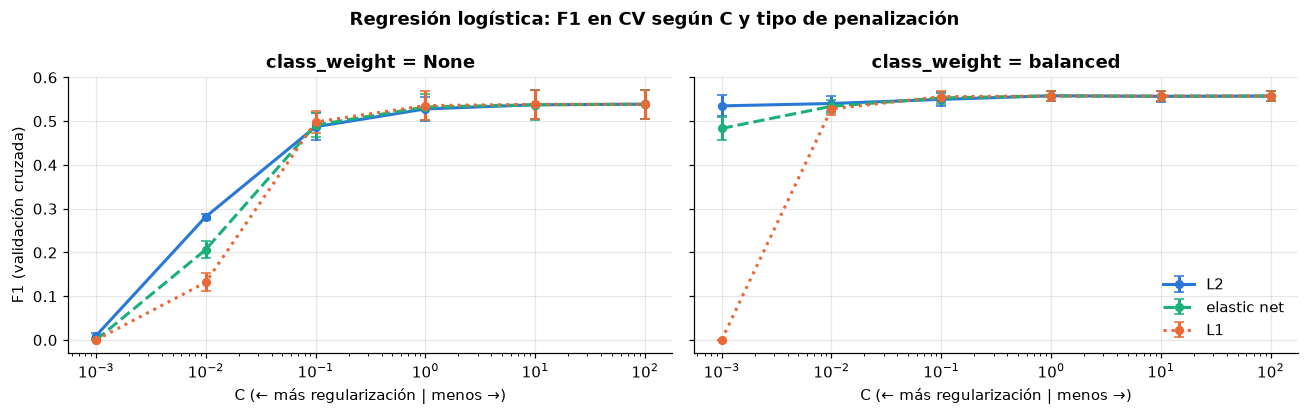

In [8]:
r = pd.DataFrame(gs_lr.cv_results_)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
for ax, cw in zip(axes, [None, "balanced"]):
    for l1, col, ls in zip([0.0, 0.5, 1.0], [C_LR, "#1baf7a", C_DT], ["-", "--", ":"]):
        sub = r[(r.param_modelo__l1_ratio == l1) & (r.param_modelo__class_weight.astype(object).fillna("None").astype(str) == str(cw))].sort_values("param_modelo__C")
        ax.errorbar(sub.param_modelo__C.astype(float), sub.mean_test_f1, yerr=sub.std_test_f1, marker="o", ms=5,
                    capsize=3, color=col, ls=ls, lw=2, label={0.0: "L2", 0.5: "elastic net", 1.0: "L1"}[l1])
    ax.set_xscale("log"); ax.set_xlabel("C (← más regularización | menos →)"); ax.set_title(f"class_weight = {cw}")
axes[0].set_ylabel("F1 (validación cruzada)"); axes[1].legend(frameon=False)
fig.suptitle("Regresión logística: F1 en CV según C y tipo de penalización", fontweight="bold")
plt.tight_layout(); plt.savefig(FIG_DIR / "02_lr_hiperparametros.png", bbox_inches="tight"); plt.show()

**Lectura.**

- **Regularización muy fuerte (C = 0,001) destruye el modelo.** Con L1 todos los coeficientes llegan a cero y el modelo predice siempre la misma clase (F1 = 0). Sin `class_weight`, incluso L2 colapsa: con coeficientes tan pequeños, ninguna probabilidad supera 0,5.
- **`class_weight="balanced"` mejora el F1** (≈ 0,56 contra ≈ 0,54) porque desplaza las probabilidades hacia la clase minoritaria y aumenta el recall.
- **Desde C ≈ 0,1 las curvas se aplanan** y el tipo de penalización casi no importa. Con solo 11 variables, todas informativas, y 6.000 registros, el modelo no tiene suficiente capacidad para sobreajustar, así que la regularización fuerte no aporta.
- **Mejor combinación: C = 1, L2 (Ridge), `balanced`.** Las diferencias con sus vecinas están en la cuarta cifra decimal: el resultado es robusto a la elección exacta del hiperparámetro.

### 4.2 Árbol de decisión

| Hiperparámetro | Valores | Significado |
|---|---|---|
| `max_depth` | 2 · 3 · 4 · 5 · 6 · 7 · 8 · 10 · None | Profundidad máxima: controla la complejidad (sesgo vs. varianza) |
| `min_samples_leaf` | 1 · 5 · 10 · 20 · 50 · 100 | Mínimo de clientes por hoja: evita reglas basadas en muy pocos casos |
| `criterion` | gini · entropy | Medida de impureza para elegir las divisiones |
| `class_weight` | None · balanced | Igual que en la regresión logística |

In [9]:
pipe_dt = Pipeline([("pre", make_preprocessor(lineal=False)),
                    ("modelo", DecisionTreeClassifier(random_state=SEED))])
grid_dt = {"modelo__max_depth": [2, 3, 4, 5, 6, 7, 8, 10, None],
           "modelo__min_samples_leaf": [1, 5, 10, 20, 50, 100],
           "modelo__criterion": ["gini", "entropy"],
           "modelo__class_weight": [None, "balanced"]}


def regla_un_error_estandar(cv_results):
    """Elige el árbol MÁS SIMPLE cuyo F1 en CV esté a menos de 1 error estándar del mejor."""
    r = pd.DataFrame(cv_results)
    mejor = r["mean_test_f1"].idxmax()
    umbral = r.loc[mejor, "mean_test_f1"] - r.loc[mejor, "std_test_f1"] / np.sqrt(cv.get_n_splits())
    cand = r[r["mean_test_f1"] >= umbral].copy()
    cand["prof"] = cand["param_modelo__max_depth"].astype(object).fillna(1000).astype(int)
    cand = cand.sort_values(["prof", "param_modelo__min_samples_leaf", "mean_test_f1"], ascending=[True, False, False])
    return int(cand.index[0])

gs_dt = GridSearchCV(pipe_dt, grid_dt, scoring=SCORING, refit=regla_un_error_estandar, cv=cv, n_jobs=-1,
                     return_train_score=True)
gs_dt.fit(X_train, y_train)
r_dt = pd.DataFrame(gs_dt.cv_results_)
i_max = r_dt["mean_test_f1"].idxmax()
print("F1 CV máximo:", round(r_dt.loc[i_max, "mean_test_f1"], 4), "con", r_dt.loc[i_max, "params"])
print("Elegido (regla 1-EE):", gs_dt.best_params_, f"| F1 CV = {r_dt.loc[gs_dt.best_index_, 'mean_test_f1']:.4f}")
tabla_cv(gs_dt)

F1 CV máximo: 0.5719 con {'modelo__class_weight': None, 'modelo__criterion': 'gini', 'modelo__max_depth': None, 'modelo__min_samples_leaf': 10}
Elegido (regla 1-EE): {'modelo__class_weight': 'balanced', 'modelo__criterion': 'entropy', 'modelo__max_depth': 5, 'modelo__min_samples_leaf': 50} | F1 CV = 0.5649


,class_weight,criterion,max_depth,min_samples_leaf,mean_train_f1,mean_test_f1,std_test_f1,mean_test_roc_auc,mean_test_ap,rank_test_f1
50,NaN,gini,None,10,0.6767,0.5719,0.0240,0.8005,0.5901,1
38,NaN,gini,8,10,0.6283,0.5716,0.0182,0.8257,0.6168,2
36,NaN,gini,8,1,0.6666,0.5700,0.0167,0.8057,0.5786,3
187,balanced,entropy,6,5,0.6014,0.5681,0.0136,0.8321,0.6020,4
37,NaN,gini,8,5,0.6388,0.5678,0.0188,0.8212,0.6112,5
128,balanced,gini,5,10,0.5781,0.5674,0.0223,0.8352,0.5848,6
126,balanced,gini,5,1,0.5798,0.5674,0.0223,0.8359,0.5842,7
127,balanced,gini,5,5,0.5786,0.5673,0.0218,0.8352,0.5873,8


**¿Por qué no se toma simplemente el árbol con mayor F1?** El árbol con el F1 de CV más alto no tiene límite de profundidad (`max_depth=None`) y queda con más de 300 hojas: memoriza el entrenamiento (F1 ≈ 0,68 en entrenamiento contra ≈ 0,57 en CV). Muchas configuraciones mucho más simples quedan a menos de un error estándar de distancia, así que la diferencia **no es distinguible del ruido** de la validación cruzada. Se aplica la **regla de un error estándar** (Hastie, Tibshirani & Friedman, *The Elements of Statistical Learning*, §7.10): entre los modelos cuyo F1 medio está a menos de 1 EE del mejor, se elige el **más simple** (menor profundidad y, a igual profundidad, hojas más grandes). Así se obtiene un árbol que generaliza mejor y que se puede leer e interpretar.

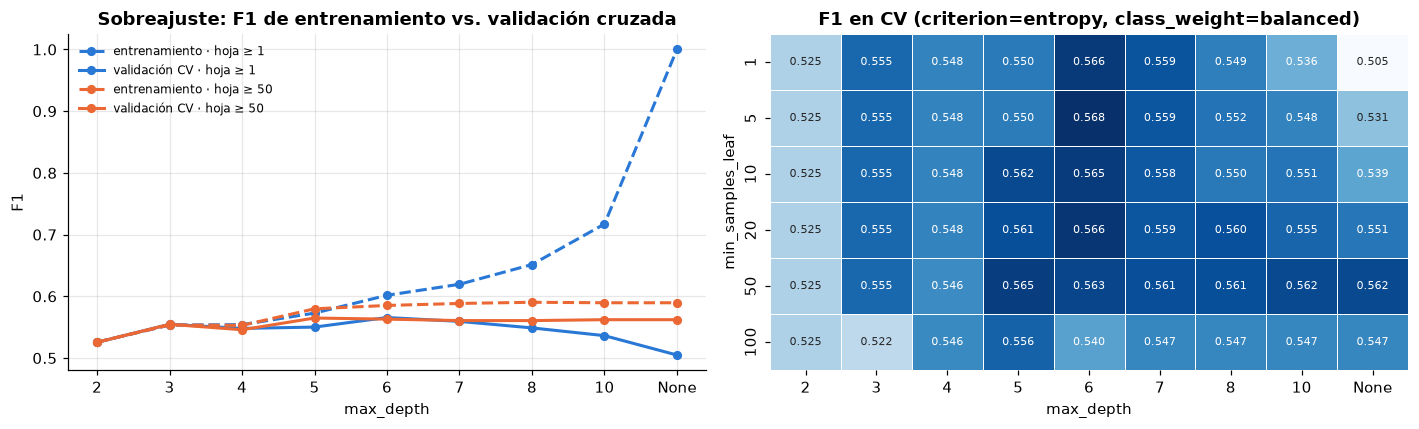

In [10]:
r = pd.DataFrame(gs_dt.cv_results_)
bp = gs_dt.best_params_
r["prof"] = r.param_modelo__max_depth.astype(object).fillna(99).astype(int)
r["cw"] = r.param_modelo__class_weight.astype(object).fillna("None").astype(str)
fijo = r[(r.param_modelo__criterion == bp["modelo__criterion"]) & (r.cw == str(bp["modelo__class_weight"]))]
etq = [str(p) if p != 99 else "None" for p in sorted(fijo.prof.unique())]

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for hoja, col in [(1, C_LR), (bp["modelo__min_samples_leaf"], C_DT)]:
    sub = fijo[fijo.param_modelo__min_samples_leaf == hoja].sort_values("prof")
    axes[0].plot(etq, sub.mean_train_f1, marker="o", ms=5, color=col, lw=2, ls="--", label=f"entrenamiento · hoja ≥ {hoja}")
    axes[0].plot(etq, sub.mean_test_f1, marker="o", ms=5, color=col, lw=2, label=f"validación CV · hoja ≥ {hoja}")
axes[0].set_xlabel("max_depth"); axes[0].set_ylabel("F1"); axes[0].legend(frameon=False, fontsize=8)
axes[0].set_title("Sobreajuste: F1 de entrenamiento vs. validación cruzada")

piv = fijo.assign(max_depth=fijo.prof.map(lambda p: str(p) if p != 99 else "None"))
piv = piv.pivot_table(index="param_modelo__min_samples_leaf", columns="max_depth", values="mean_test_f1")[etq]
sns.heatmap(piv, annot=True, fmt=".3f", cmap="Blues", ax=axes[1], cbar=False, annot_kws={"size": 7}, linewidths=0.5)
axes[1].grid(False)
axes[1].set_ylabel("min_samples_leaf"); axes[1].set_title(f"F1 en CV (criterion={bp['modelo__criterion']}, class_weight={bp['modelo__class_weight']})")
plt.tight_layout(); plt.savefig(FIG_DIR / "02_dt_hiperparametros.png", bbox_inches="tight"); plt.show()

**Lectura (compromiso sesgo–varianza).**

- Con profundidad 2–3 el árbol tiene **sesgo alto**: pocas particiones y F1 bajo tanto en entrenamiento como en validación (las curvas coinciden).
- Al profundizar, el F1 de entrenamiento sigue subiendo, pero el de validación se estanca alrededor de 0,56. Con **hojas de 1 cliente** (líneas azules), el árbol sin límite de profundidad memoriza el entrenamiento: su F1 de entrenamiento se dispara mientras el de validación cae. Es **varianza alta**.
- `min_samples_leaf` funciona como regularización: con hojas de al menos 50 clientes (líneas naranjas) la brecha se reduce mucho, porque ninguna regla se apoya en pocos casos.
- El árbol elegido (**profundidad 5, hojas ≥ 50, criterio *entropy*, `class_weight="balanced"`**) está en la zona donde la validación ya alcanzó su máximo y la brecha todavía es pequeña.

### 4.3 Modelos finales

`GridSearchCV` reentrena automáticamente cada modelo con su mejor combinación sobre todo el conjunto de entrenamiento. Estos modelos se usan en el resto del notebook (evaluación e interpretación).

In [11]:
lr, dt = gs_lr.best_estimator_, gs_dt.best_estimator_
MODELOS = {"Regresión logística": lr, "Árbol de decisión": dt}
COLORES = {"Regresión logística": C_LR, "Árbol de decisión": C_DT}
print("Hojas del árbol:", dt.named_steps["modelo"].get_n_leaves(), "| profundidad:", dt.named_steps["modelo"].get_depth())

Hojas del árbol: 29 | profundidad: 5


## 5. Análisis cuantitativo
### 5.1 Métricas en entrenamiento y validación (umbral 0,5)

| Métrica | Pregunta de negocio que responde |
|---|---|
| **Accuracy** | ¿Qué porcentaje de clientes clasifica bien? Engañosa con desbalance: el baseline ya obtiene ~80 %. |
| **Precisión** | De los clientes que el modelo marca como "en riesgo" (los que se contactarían), ¿cuántos realmente se iban a ir? Mide **cuánto del gasto de campaña llega a clientes correctos**. |
| **Recall** | De todos los clientes que se iban a ir, ¿a cuántos detecta? Mide **qué parte del ingreso en riesgo se puede intentar salvar**. |
| **F1** | Media armónica de precisión y recall: resume el equilibrio entre ambos. |
| **AUC-ROC** | Probabilidad de que un cliente que abandona reciba un puntaje mayor que uno que no. Mide la capacidad de **ordenar** clientes por riesgo, sin depender del umbral. |
| **AP (PR-AUC)** | Precisión promedio a lo largo de todos los niveles de recall. Más exigente que el AUC con clases desbalanceadas. Su valor de referencia es la tasa de abandono (~0,20). |

In [12]:
def metricas(modelo, X, y, umbral=0.5):
    p = modelo.predict_proba(X)[:, 1]
    yhat = (p >= umbral).astype(int)
    return {"accuracy": accuracy_score(y, yhat), "precisión": precision_score(y, yhat, zero_division=0),
            "recall": recall_score(y, yhat), "F1": f1_score(y, yhat),
            "AUC-ROC": roc_auc_score(y, p), "AP": average_precision_score(y, p)}

filas = {}
for nombre, m in {**MODELOS, "Baseline (mayoritaria)": dummy}.items():
    for conj, (Xc, yc) in {"entrenamiento": (X_train, y_train), "validación": (X_val, y_val)}.items():
        filas[(nombre, conj)] = metricas(m, Xc, yc)
tabla = pd.DataFrame(filas).T
display(tabla.style.format("{:.3f}").background_gradient(cmap="Blues", axis=0, subset=pd.IndexSlice[:, ["F1", "AUC-ROC", "AP"]]))

brecha = (tabla.xs("entrenamiento", level=1) - tabla.xs("validación", level=1)).loc[list(MODELOS)]
print("Brecha entrenamiento – validación:"); display(brecha.round(3))

Brecha entrenamiento – validación:


,accuracy,precisión,recall,F1,AUC-ROC,AP
Regresión logística,-0.0050,-0.0080,-0.0100,-0.0090,0.0050,0.0180
Árbol de decisión,0.0020,0.0040,0.0290,0.0110,0.0210,0.0250


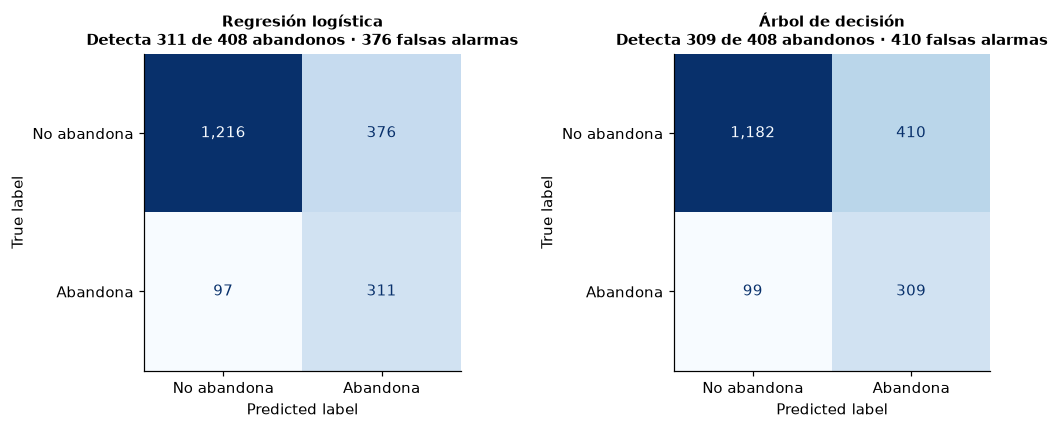

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, (nombre, m) in zip(axes, MODELOS.items()):
    cm = confusion_matrix(y_val, m.predict(X_val))
    ConfusionMatrixDisplay(cm, display_labels=["No abandona", "Abandona"]).plot(ax=ax, cmap="Blues", colorbar=False, values_format=",")
    tn, fp, fn, tp = cm.ravel()
    ax.set_title(f"{nombre}\nDetecta {tp} de {tp + fn} abandonos · {fp} falsas alarmas", fontsize=10)
    ax.grid(False)
plt.tight_layout(); plt.savefig(FIG_DIR / "02_matrices_confusion_val.png", bbox_inches="tight"); plt.show()

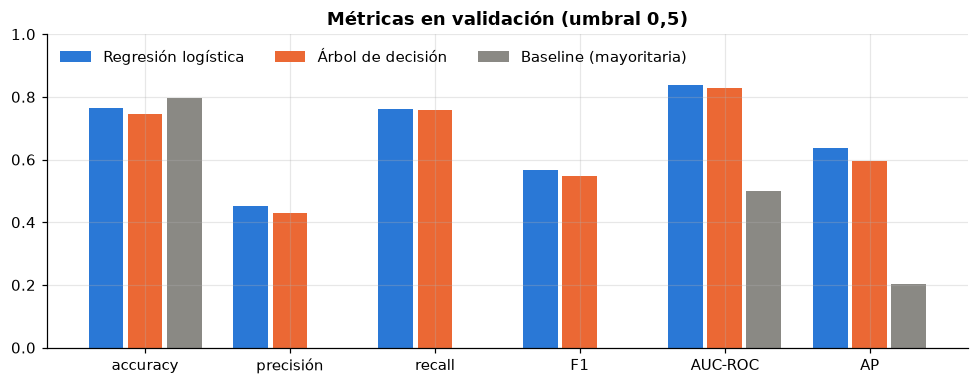

In [14]:
fig, ax = plt.subplots(figsize=(9, 3.6))
mets = ["accuracy", "precisión", "recall", "F1", "AUC-ROC", "AP"]
val = tabla.xs("validación", level=1).loc[list(MODELOS) + ["Baseline (mayoritaria)"], mets]
x = np.arange(len(mets)); w = 0.27
for i, (nombre, col) in enumerate(zip(val.index, [C_LR, C_DT, C_GRIS])):
    ax.bar(x + (i - 1) * w, val.loc[nombre], w - 0.03, color=col, label=nombre)
ax.set_xticks(x, mets); ax.set_ylim(0, 1); ax.legend(frameon=False, ncol=3, loc="upper left")
ax.set_title("Métricas en validación (umbral 0,5)")
plt.tight_layout(); plt.savefig(FIG_DIR / "02_metricas_val.png", bbox_inches="tight"); plt.show()

### 5.2 Curvas precisión–recall y ROC

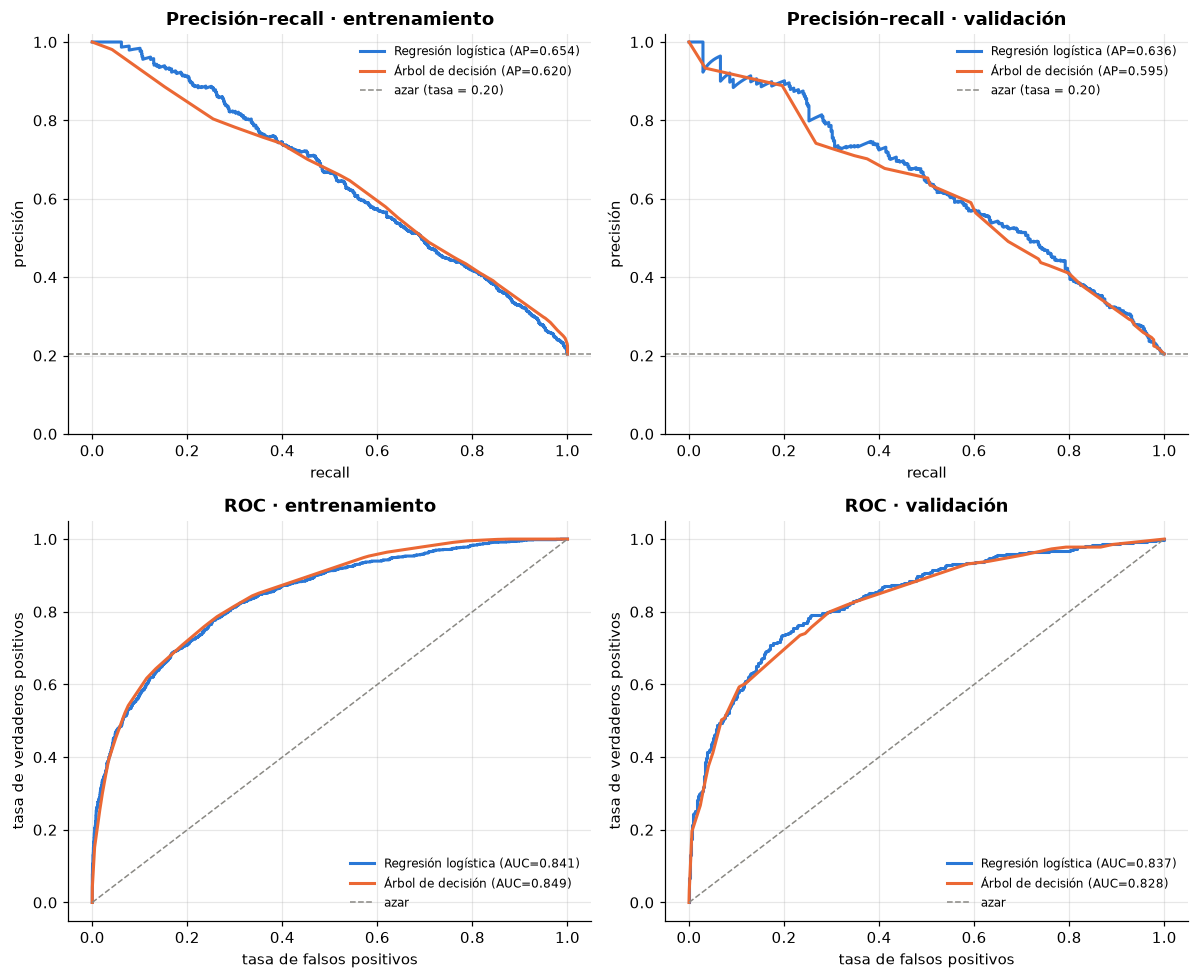

In [15]:
fig, axes = plt.subplots(2, 2, figsize=(11, 9))
for j, (conj, (Xc, yc)) in enumerate({"entrenamiento": (X_train, y_train), "validación": (X_val, y_val)}.items()):
    for nombre, m in MODELOS.items():
        p = m.predict_proba(Xc)[:, 1]
        pr, rc, _ = precision_recall_curve(yc, p)
        axes[0, j].plot(rc, pr, color=COLORES[nombre], lw=2, label=f"{nombre} (AP={average_precision_score(yc, p):.3f})")
        fpr, tpr, _ = roc_curve(yc, p)
        axes[1, j].plot(fpr, tpr, color=COLORES[nombre], lw=2, label=f"{nombre} (AUC={roc_auc_score(yc, p):.3f})")
    axes[0, j].axhline(yc.mean(), color=C_GRIS, ls="--", lw=1, label=f"azar (tasa = {yc.mean():.2f})")
    axes[1, j].plot([0, 1], [0, 1], color=C_GRIS, ls="--", lw=1, label="azar")
    axes[0, j].set(title=f"Precisión–recall · {conj}", xlabel="recall", ylabel="precisión", ylim=(0, 1.02))
    axes[1, j].set(title=f"ROC · {conj}", xlabel="tasa de falsos positivos", ylabel="tasa de verdaderos positivos")
    for ax in axes[:, j]: ax.legend(frameon=False, fontsize=8, loc="best")
plt.tight_layout(); plt.savefig(FIG_DIR / "02_curvas_pr_roc.png", bbox_inches="tight"); plt.show()

**Lectura de las curvas**

- **Línea base.** En la curva PR, la referencia es la tasa de abandono (~0,20), no 0,5: un clasificador al azar tiene precisión igual a la prevalencia. En la ROC, la referencia es la diagonal.
- **La ROC luce más optimista que la PR.** El eje x de la ROC (tasa de falsos positivos) se divide entre los ~1.600 no-abandonos de validación, así que muchas falsas alarmas producen una TFP pequeña. La precisión, en cambio, sí refleja que por cada abandono detectado se contacta a varios clientes que no se iban a ir. Para una campaña donde **se paga por cada contacto**, la curva PR describe mejor la realidad.
- La comparación entre entrenamiento y validación indica cuánto se sobreajusta cada modelo (sección 5.4).

### 5.3 ¿La diferencia entre los modelos es estadísticamente significativa?

- **Prueba de McNemar:** compara los errores de los dos modelos sobre los mismos clientes de validación. H₀: ambos modelos se equivocan con la misma frecuencia.
- **Bootstrap (2.000 remuestreos):** intervalo de confianza del 95 % para la diferencia de F1, AUC y AP (árbol − regresión).

In [16]:
yhat_lr, yhat_dt = lr.predict(X_val), dt.predict(X_val)
ok_lr, ok_dt = yhat_lr == y_val.values, yhat_dt == y_val.values
tabla_mc = [[np.sum(ok_lr & ok_dt), np.sum(ok_lr & ~ok_dt)], [np.sum(~ok_lr & ok_dt), np.sum(~ok_lr & ~ok_dt)]]
res = mcnemar(tabla_mc, exact=False, correction=True)
print(pd.DataFrame(tabla_mc, index=["LR acierta", "LR falla"], columns=["DT acierta", "DT falla"]))
print(f"McNemar: estadístico = {res.statistic:.2f}, p-valor = {res.pvalue:.4f}")

rng = np.random.default_rng(SEED)
p_lr, p_dt, yv = lr.predict_proba(X_val)[:, 1], dt.predict_proba(X_val)[:, 1], y_val.values
difs = []
for _ in range(2000):
    i = rng.integers(0, len(yv), len(yv))
    difs.append([f1_score(yv[i], p_dt[i] >= .5) - f1_score(yv[i], p_lr[i] >= .5),
                 roc_auc_score(yv[i], p_dt[i]) - roc_auc_score(yv[i], p_lr[i]),
                 average_precision_score(yv[i], p_dt[i]) - average_precision_score(yv[i], p_lr[i])])
difs = pd.DataFrame(difs, columns=["ΔF1", "ΔAUC", "ΔAP"])
ic = difs.quantile([0.025, 0.5, 0.975]).T
ic.columns = ["IC 2,5 %", "mediana", "IC 97,5 %"]
ic["¿incluye 0?"] = (ic["IC 2,5 %"] < 0) & (ic["IC 97,5 %"] > 0)
ic

            DT acierta  DT falla
LR acierta        1357       170
LR falla           134       339
McNemar: estadístico = 4.03, p-valor = 0.0447


,"IC 2,5 %",mediana,"IC 97,5 %",¿incluye 0?
ΔF1,-0.0437,-0.0197,0.0029,True
ΔAUC,-0.0233,-0.0085,0.0065,True
ΔAP,-0.0725,-0.0409,-0.0080,False


### 5.4 ¿Qué elementos impactaron positivamente las métricas? (ablación)

Se parte de la regresión logística final y se cambia **una decisión a la vez**, midiendo el efecto con la misma validación cruzada de 5 *folds* sobre el entrenamiento (sin tocar validación ni prueba).

In [17]:
from sklearn.model_selection import cross_validate
mp = make_preprocessor

def lr_variante(edad_cuadrado=True, productos_categorica=True, class_weight="balanced", C=1.0):
    return Pipeline([("pre", mp(lineal=True, edad_cuadrado=edad_cuadrado, productos_categorica=productos_categorica)),
                     ("modelo", LogisticRegression(solver="saga", max_iter=10000, C=C, l1_ratio=0.0,
                                                   class_weight=class_weight, random_state=SEED))])

variantes = {
    "Modelo final (age_sq + productos one-hot + balanced, C=1)": lr_variante(),
    "Sin age_sq (edad solo lineal)": lr_variante(edad_cuadrado=False),
    "products_number como numérica": lr_variante(productos_categorica=False),
    "Sin class_weight": lr_variante(class_weight=None),
    "Regularización fuerte (C=0,01)": lr_variante(C=0.01),
}
filas = {}
for nombre, m in variantes.items():
    cvr = cross_validate(m, X_train, y_train, cv=cv, scoring=SCORING)
    filas[nombre] = {k: cvr[f"test_{k}"].mean() for k in SCORING}
abl = pd.DataFrame(filas).T.rename(columns={"f1": "F1", "roc_auc": "AUC-ROC", "ap": "AP"})
abl_delta = abl - abl.iloc[0]
display(abl.round(3))
print("Diferencia frente al modelo final:"); abl_delta.iloc[1:].round(3)

,F1,AUC-ROC,AP
"Modelo final (age_sq + productos one-hot + balanced, C=1)",0.5580,0.8390,0.6520
Sin age_sq (edad solo lineal),0.5510,0.8300,0.6120
products_number como numérica,0.4960,0.7820,0.5320
Sin class_weight,0.5280,0.8400,0.6570
"Regularización fuerte (C=0,01)",0.5400,0.8210,0.5330


Diferencia frente al modelo final:


,F1,AUC-ROC,AP
Sin age_sq (edad solo lineal),-0.0070,-0.0100,-0.0400
products_number como numérica,-0.0620,-0.0580,-0.1200
Sin class_weight,-0.0300,0.0000,0.0050
"Regularización fuerte (C=0,01)",-0.0180,-0.0180,-0.1190


**Lectura de la ablación**

| Decisión | Efecto al quitarla | Explicación |
|---|---|---|
| **`products_number` como categórica** | **−0,12 AP, −0,06 F1, −0,06 AUC** (el mayor impacto) | La relación es no monótona: 2 productos ≈ 8 % de abandono, 1 producto ≈ 28 %, 3–4 productos > 80 %. Como número, el modelo solo puede representar "más productos → más (o menos) riesgo" y pierde la señal más fuerte del dataset. Confirma la decisión del notebook 01. |
| **`age_sq` (variable derivada)** | −0,04 AP, −0,01 AUC | Sin el término cuadrático, el modelo supone que el riesgo crece sin límite con la edad, cuando en realidad cae después de los 60. |
| **`class_weight="balanced"`** | −0,03 F1; AUC y AP iguales | No cambia **cómo ordena** a los clientes (AUC y AP se mantienen), solo **dónde cae el umbral de 0,5**. Con pesos, el umbral 0,5 queda en un punto con mayor recall y mejor F1. Mover el umbral tendría un efecto similar (análisis de valor de negocio). |
| **Regularización moderada (C = 1 frente a C = 0,01)** | −0,12 AP con C = 0,01 | Una penalización demasiado fuerte encoge los coeficientes de las variables informativas (sobre todo las de productos 3–4) y el modelo pierde poder de discriminación. |

### 5.5 Selección del modelo

Criterio (guía del curso): **mayor F1 en validación**. Si la diferencia es pequeña o no significativa, se prefiere el modelo **más simple o con menor brecha** entre entrenamiento y validación.

In [18]:
val_f1 = tabla.xs("validación", level=1).loc[list(MODELOS), "F1"]
resumen_sel = pd.DataFrame({
    "F1 validación": val_f1,
    "AUC validación": tabla.xs("validación", level=1).loc[list(MODELOS), "AUC-ROC"],
    "AP validación": tabla.xs("validación", level=1).loc[list(MODELOS), "AP"],
    "brecha F1 (train − val)": brecha["F1"],
})
display(resumen_sel.round(3))

,F1 validación,AUC validación,AP validación,brecha F1 (train − val)
Regresión logística,0.5680,0.8370,0.6360,-0.0090
Árbol de decisión,0.5480,0.8280,0.5950,0.0110


**Modelo elegido: regresión logística regularizada (L2, C = 1, `class_weight="balanced"`).**

| Criterio | Regresión logística | Árbol de decisión | Comentario |
|---|---|---|---|
| F1 validación | **0,568** | 0,548 | Mejor F1 → criterio principal. |
| AUC-ROC validación | **0,837** | 0,828 | Diferencia pequeña; el IC 95 % bootstrap de ΔAUC incluye 0. |
| AP validación | **0,636** | 0,595 | **Diferencia significativa**: el IC 95 % de ΔAP [−0,07; −0,01] excluye 0. La regresión ordena mejor a los clientes de mayor riesgo, justo los que primero se contactarían. |
| McNemar | 170 casos en que solo acierta la RL | 134 en que solo acierta el árbol | p = 0,045: los errores difieren y la RL comete menos. |
| Brecha F1 train − val | **−0,009** | 0,011 | Ninguno sobreajusta; la RL es más estable. |
| Complejidad | 11 coeficientes | 29 hojas, profundidad 5 | La RL es una fórmula: fácil de implementar, auditar y explicar al regulador. |

La diferencia en F1 por sí sola no es concluyente (el IC de ΔF1 incluye 0), pero **la regresión logística es igual o mejor en todas las métricas, mejor de forma significativa en AP, más simple y más estable**. El árbol no se descarta: sus reglas son fáciles de comunicar y se usan en la Parte II para describir segmentos de riesgo.

## 6. Evaluación final en el conjunto de prueba

El conjunto de prueba se usa aquí por primera vez. Se reportan ambos modelos por transparencia, pero **la decisión ya se tomó con validación**.

In [19]:
ELEGIDO = "Regresión logística"
modelo = MODELOS[ELEGIDO]

filas = {}
for nombre, m in {**MODELOS, "Baseline (mayoritaria)": dummy}.items():
    filas[(nombre, "validación")] = metricas(m, X_val, y_val)
    filas[(nombre, "prueba")] = metricas(m, X_test, y_test)
tabla_test = pd.DataFrame(filas).T
display(tabla_test.style.format("{:.3f}"))

# IC 95 % por bootstrap de las métricas del modelo elegido en prueba
p_te, yt = modelo.predict_proba(X_test)[:, 1], y_test.values
boot = []
for _ in range(2000):
    i = rng.integers(0, len(yt), len(yt))
    yh = p_te[i] >= 0.5
    boot.append([precision_score(yt[i], yh), recall_score(yt[i], yh), f1_score(yt[i], yh),
                 roc_auc_score(yt[i], p_te[i]), average_precision_score(yt[i], p_te[i])])
ic_test = pd.DataFrame(boot, columns=["precisión", "recall", "F1", "AUC-ROC", "AP"]).quantile([0.025, 0.975]).T
ic_test.columns = ["IC 2,5 %", "IC 97,5 %"]
ic_test.insert(0, "prueba", tabla_test.loc[(ELEGIDO, "prueba"), ic_test.index].values)
print(f"{ELEGIDO} – métricas en prueba con IC 95 % (bootstrap):"); ic_test.round(3)

Regresión logística – métricas en prueba con IC 95 % (bootstrap):


,prueba,"IC 2,5 %","IC 97,5 %"
precisión,0.4490,0.4120,0.4860
recall,0.7490,0.7070,0.7920
F1,0.5620,0.5250,0.5950
AUC-ROC,0.8400,0.8160,0.8620
AP,0.6630,0.6150,0.7070


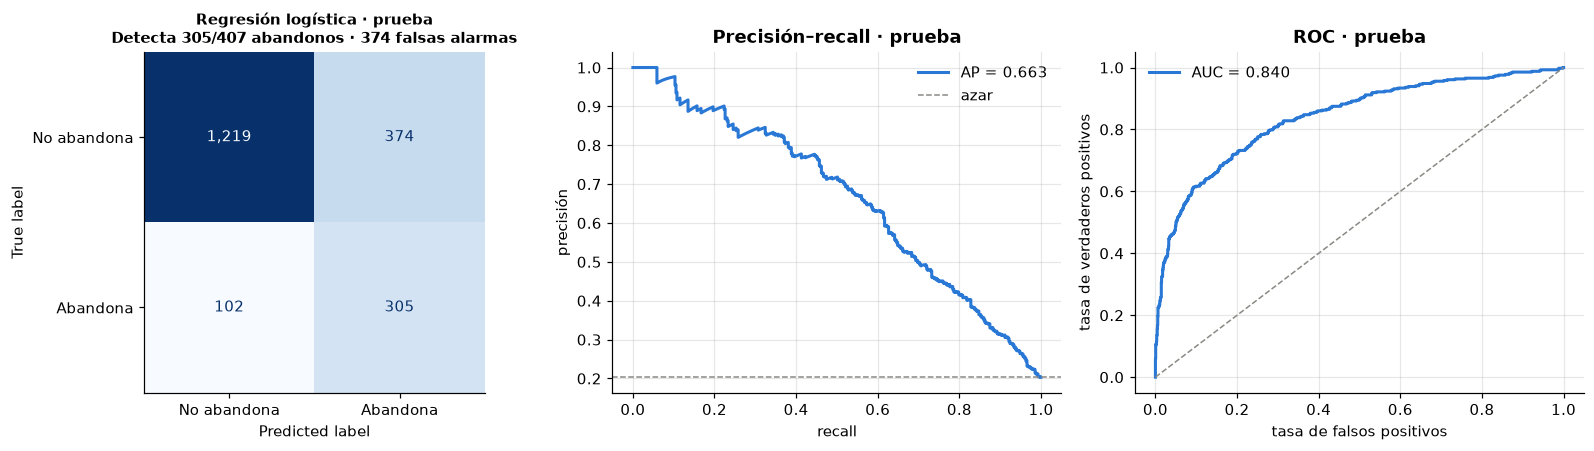

Accuracy baseline: 0.796 | Accuracy Regresión logística: 0.762
El baseline detecta 0 de 407 abandonos; el modelo detecta 305 (75%).


In [20]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
cm = confusion_matrix(y_test, modelo.predict(X_test))
ConfusionMatrixDisplay(cm, display_labels=["No abandona", "Abandona"]).plot(ax=axes[0], cmap="Blues", colorbar=False, values_format=",")
tn, fp, fn, tp = cm.ravel(); axes[0].grid(False)
axes[0].set_title(f"{ELEGIDO} · prueba\nDetecta {tp}/{tp + fn} abandonos · {fp} falsas alarmas", fontsize=10)

pr, rc, _ = precision_recall_curve(y_test, p_te)
axes[1].plot(rc, pr, color=COLORES[ELEGIDO], lw=2, label=f"AP = {average_precision_score(y_test, p_te):.3f}")
axes[1].axhline(y_test.mean(), color=C_GRIS, ls="--", lw=1, label="azar")
axes[1].set(title="Precisión–recall · prueba", xlabel="recall", ylabel="precisión"); axes[1].legend(frameon=False)
fpr, tpr, _ = roc_curve(y_test, p_te)
axes[2].plot(fpr, tpr, color=COLORES[ELEGIDO], lw=2, label=f"AUC = {roc_auc_score(y_test, p_te):.3f}")
axes[2].plot([0, 1], [0, 1], color=C_GRIS, ls="--", lw=1)
axes[2].set(title="ROC · prueba", xlabel="tasa de falsos positivos", ylabel="tasa de verdaderos positivos"); axes[2].legend(frameon=False)
plt.tight_layout(); plt.savefig(FIG_DIR / "02_prueba_modelo_elegido.png", bbox_inches="tight"); plt.show()

acc_base = accuracy_score(y_test, dummy.predict(X_test))
acc_mod = accuracy_score(y_test, modelo.predict(X_test))
print(f"Accuracy baseline: {acc_base:.3f} | Accuracy {ELEGIDO}: {acc_mod:.3f}")
print(f"El baseline detecta 0 de {y_test.sum()} abandonos; el modelo detecta {tp} ({tp / y_test.sum():.0%}).")

### 6.1 Efecto del umbral de decisión

El umbral 0,5 es arbitrario. Bajarlo detecta más abandonos (más recall) a costa de más contactos innecesarios (menos precisión). En el análisis de valor de negocio se elige el umbral que **maximiza la ganancia económica**. Aquí se muestra el compromiso en validación.

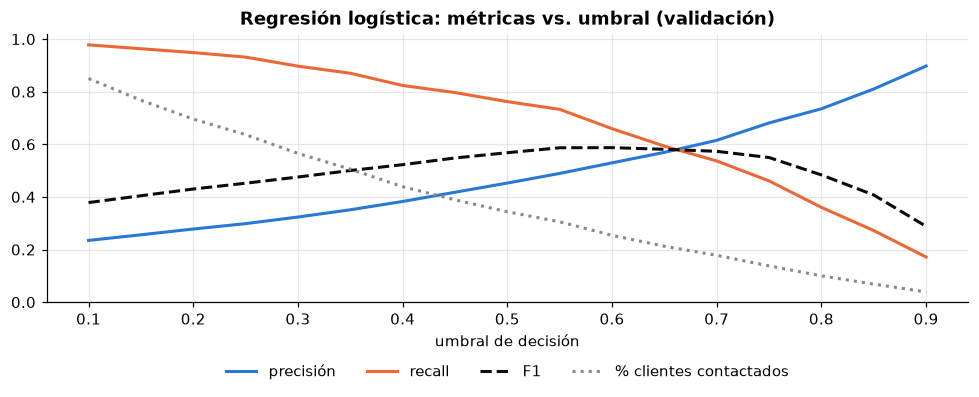

,precisión,recall,F1,% clientes contactados
umbral,,,,
0.1000,0.2350,0.9780,0.3790,0.8500
0.2000,0.2780,0.9490,0.4300,0.6960
0.3000,0.3240,0.8970,0.4760,0.5660
0.4000,0.3830,0.8240,0.5230,0.4390
0.5000,0.4530,0.7620,0.5680,0.3440
0.6000,0.5300,0.6590,0.5870,0.2540
0.7000,0.6150,0.5370,0.5730,0.1780
0.8000,0.7350,0.3600,0.4840,0.1000
0.9000,0.8970,0.1720,0.2880,0.0390


In [21]:
umbrales = np.round(np.arange(0.1, 0.91, 0.05), 2)
p_val = modelo.predict_proba(X_val)[:, 1]
tu = pd.DataFrame([{"umbral": u, "precisión": precision_score(y_val, p_val >= u, zero_division=0),
                    "recall": recall_score(y_val, p_val >= u), "F1": f1_score(y_val, p_val >= u),
                    "% clientes contactados": (p_val >= u).mean()} for u in umbrales]).set_index("umbral")
fig, ax = plt.subplots(figsize=(9, 3.8))
for c, col, ls in zip(["precisión", "recall", "F1", "% clientes contactados"], [C_LR, C_DT, "#0b0b0b", C_GRIS], ["-", "-", "--", ":"]):
    ax.plot(tu.index, tu[c], color=col, lw=2, ls=ls, label=c)
ax.set(xlabel="umbral de decisión", ylim=(0, 1.02), title=f"{ELEGIDO}: métricas vs. umbral (validación)")
ax.legend(frameon=False, ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.18))
plt.tight_layout(); plt.savefig(FIG_DIR / "02_umbral.png", bbox_inches="tight"); plt.show()
tu.iloc[::2].round(3)

### 6.2 Desempeño por segmento (prueba)

Se revisa si el modelo funciona igual de bien en todos los grupos de clientes.

In [22]:
te = X_test.assign(churn=y_test.values, p=p_te, pred=(p_te >= 0.5).astype(int))
te["rango_edad"] = pd.cut(te["age"], [17, 35, 45, 55, 100], labels=["18–35", "36–45", "46–55", "56+"])
filas = []
for var in ["country", "gender", "products_number", "active_member", "rango_edad"]:
    for val_, g in te.groupby(var, observed=True):
        filas.append({"variable": var, "grupo": val_, "n": len(g), "tasa real": g.churn.mean(),
                      "tasa predicha": g.pred.mean(), "precisión": precision_score(g.churn, g.pred, zero_division=0),
                      "recall": recall_score(g.churn, g.pred, zero_division=0)})
seg = pd.DataFrame(filas).set_index(["variable", "grupo"])
seg.style.format({"n": "{:,.0f}", "tasa real": "{:.1%}", "tasa predicha": "{:.1%}", "precisión": "{:.2f}", "recall": "{:.2f}"})

## 7. Conclusiones del análisis cuantitativo

**1. El desempeño se mantiene en prueba (no hubo sobreajuste a validación).** La regresión logística obtiene en prueba F1 = 0,562 (IC 95 %: 0,53–0,60), AUC = 0,840 (0,82–0,86) y AP = 0,663 (0,62–0,71), prácticamente iguales a validación (F1 0,568, AUC 0,837). Es la mejor estimación de cómo funcionaría el modelo con clientes nuevos de la misma población.

**2. Qué significan las métricas para el negocio (umbral 0,5, conjunto de prueba):**

- **Recall = 75 %:** de cada 4 clientes que se iban a ir, el modelo detecta 3 (305 de 407). El baseline no detecta ninguno.
- **Precisión = 45 %:** de cada 100 clientes contactados, 45 realmente se iban a ir. Al azar serían 20. El modelo concentra la campaña **2,2 veces mejor que contactar al azar** (*lift*).
- **Se contacta al 34 % de la base.** El error más frecuente son los **falsos positivos** (374 contra 102 falsos negativos), consecuencia de `class_weight="balanced"`, que privilegia el recall.
- **Accuracy (0,762) menor que la del baseline (0,796).** Es la prueba de que la *accuracy* no sirve aquí: el baseline "acierta" más solo porque nunca predice abandono y no tiene ningún valor para una campaña de retención.
- **AUC = 0,84:** si se toma al azar un cliente que abandona y uno que no, el modelo le da mayor riesgo al primero el 84 % de las veces. Esto permite **priorizar** la campaña de mayor a menor riesgo según el presupuesto.

**3. Qué elementos impactaron positivamente las métricas:** (1) tratar `products_number` como categórica (el aporte más grande); (2) la variable derivada `age_sq`; (3) `class_weight="balanced"` para el F1 en el umbral 0,5; (4) la limpieza de datos (valores imposibles como edad 210 habrían distorsionado el escalado y los coeficientes); (5) una regularización moderada (C = 1); (6) la regla de 1 error estándar para el árbol, que evitó un árbol de 322 hojas sobreajustado (brecha de F1 de 0,16).

**4. Dónde falla el modelo (análisis por segmento en prueba):**

- **Clientes jóvenes (≤ 35 años):** recall de solo 0,37. Abandonan poco (10 %) y el modelo casi nunca los señala.
- **Clientes con 2 productos:** recall 0,30 y precisión 0,31. Es el segmento más "seguro" (7 % de abandono) y el modelo no distingue a los pocos que sí se van.
- **Clientes activos:** recall 0,58, frente a 0,84 en los inactivos.
- En cambio, funciona muy bien en Alemania (recall 0,87), entre 46 y 55 años (0,95) y con 3–4 productos (≈ 0,98).

**5. Oportunidades de mejora:**

- **Ajustar el umbral según la economía de la campaña** en lugar de usar 0,5 (análisis de valor de negocio).
- **Modelos de ensamble** (Random Forest, Gradient Boosting) para capturar interacciones que una regresión lineal no ve (por ejemplo edad × actividad o productos × saldo), lo que podría mejorar los segmentos débiles.
- **Más variables de comportamiento:** transacciones recientes, uso de canales digitales, quejas y PQRS ante la Superintendencia Financiera, cambios de saldo en el tiempo. Las variables actuales son "fotos" estáticas del cliente.
- **Calibrar las probabilidades** (Platt o isotónica): `class_weight="balanced"` infla las probabilidades. Si el banco quiere usarlas como "probabilidad real de abandono" (por ejemplo, para el valor esperado por cliente), deben calibrarse.
- **Validación temporal y con datos locales:** el dataset es europeo y de un solo corte en el tiempo. Antes de usarlo en un banco colombiano hay que reentrenarlo y validarlo con datos de ese banco.

---
# Parte II · Análisis cualitativo: interpretación de los modelos

Esta parte cubre el **entregable 4 (20 %)**. Busca responder **por qué** los modelos predicen lo que predicen, en dos niveles:

| Nivel | Pregunta | Técnicas |
|---|---|---|
| **Global** | ¿Qué variables mueven el riesgo de abandono y en qué dirección? | Coeficientes y razones de momios (RL), reglas e importancia del árbol, importancia por permutación, valores SHAP (resumen), gráficos ICE/PDP |
| **Local** | ¿Por qué el modelo le asignó este riesgo a **este** cliente? | Valores SHAP individuales y LIME en una muestra de clientes de prueba (aciertos y errores) |

Se interpretan los dos modelos para comparar si "razonan" igual.

In [23]:
print("Regresión logística: C =", lr.named_steps["modelo"].get_params()["C"], "| Árbol: profundidad",
      dt.named_steps["modelo"].get_depth(), "y", dt.named_steps["modelo"].get_n_leaves(), "hojas")

Regresión logística: C = 1 | Árbol: profundidad 5 y 29 hojas


## 8. Comportamiento global
### 8.1 Regresión logística: coeficientes y razones de momios

Como las variables numéricas están estandarizadas, cada coeficiente indica cuánto cambia el **log-odds de abandono** cuando la variable aumenta **una desviación estándar** (numéricas) o cuando el cliente pertenece a esa categoría frente a la de referencia (France, Female, 1 producto, inactivo). La **razón de momios** (OR = e^β) se lee como un multiplicador: OR = 2 duplica los *odds* de abandono y OR = 0,5 los reduce a la mitad.

Intercepto: 0.616


,coeficiente,razón de momios (OR),1 DE equivale a
age,3.0840,21.8390,10
products_number_4,3.0090,20.2670,
products_number_3,2.3600,10.5930,
age_sq,-2.3010,0.1000,937
products_number_2,-1.4710,0.2300,
active_member,-0.9430,0.3890,
country_Germany,0.8010,2.2280,
gender_Male,-0.5830,0.5580,
country_Spain,0.0610,1.0620,
balance,0.0190,1.0190,"61,746"


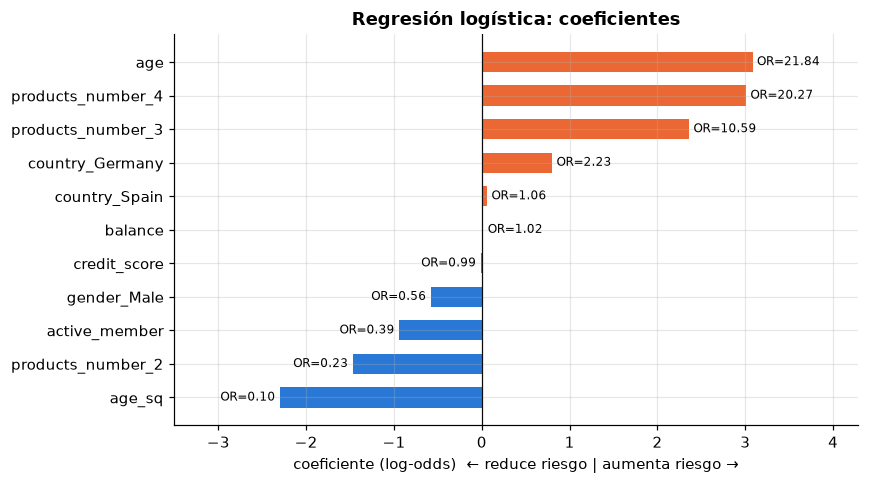

In [24]:
pre_lr, m_lr = lr.named_steps["pre"], lr.named_steps["modelo"]
nombres_lr = pre_lr.get_feature_names_out()
coef = pd.DataFrame({"coeficiente": m_lr.coef_[0], "razón de momios (OR)": np.exp(m_lr.coef_[0])}, index=nombres_lr)
coef = coef.reindex(coef["coeficiente"].abs().sort_values(ascending=False).index)
print(f"Intercepto: {m_lr.intercept_[0]:.3f}")

# desviación estándar de las numéricas (para traducir "1 DE" a unidades reales)
esc_num = pre_lr.named_transformers_["num"].named_steps["escalar"]
esc_edad = pre_lr.named_transformers_["edad"].named_steps["escalar"]
de = dict(zip(list(NUMERICAS) + ["age", "age_sq"], list(esc_num.scale_) + list(esc_edad.scale_)))
coef["1 DE equivale a"] = [f"{de[n]:,.0f}" if n in de else "" for n in coef.index]
display(coef.round(3))

fig, ax = plt.subplots(figsize=(8, 4.5))
c_ = coef["coeficiente"].sort_values()
ax.barh(c_.index, c_.values, color=[C_SI if v > 0 else C_NO for v in c_.values], height=0.6)
ax.axvline(0, color="#0b0b0b", lw=0.8)
for y_, v in enumerate(c_.values):
    ax.text(v + (0.05 if v > 0 else -0.05), y_, f"OR={np.exp(v):.2f}", va="center", ha="left" if v > 0 else "right", fontsize=8)
ax.set_xlabel("coeficiente (log-odds)  ← reduce riesgo | aumenta riesgo →")
ax.set_title("Regresión logística: coeficientes")
ax.set_xlim(c_.min() - 1.2, c_.max() + 1.2)
plt.tight_layout(); plt.savefig(FIG_DIR / "02_coeficientes_lr.png", bbox_inches="tight"); plt.show()

`age` y `age_sq` no se pueden leer por separado: juntas forman una parábola. Para ver su efecto combinado se grafica la probabilidad predicha según la edad, dejando las demás variables en sus valores típicos.

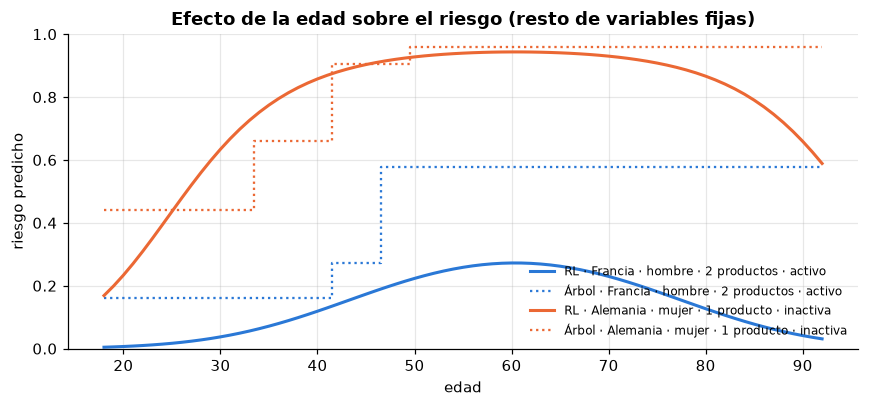

Edad de máximo riesgo según la RL: 60 años


In [25]:
edades = np.arange(18, 93)
perfiles = {"Francia · hombre · 2 productos · activo": dict(country="France", gender="Male", products_number=2, active_member=1),
            "Alemania · mujer · 1 producto · inactiva": dict(country="Germany", gender="Female", products_number=1, active_member=0)}
fig, ax = plt.subplots(figsize=(8, 3.8))
for (nombre, perfil), col in zip(perfiles.items(), [C_NO, C_SI]):
    base = pd.DataFrame({"credit_score": X_train.credit_score.median(), "balance": X_train.balance.median(), "age": edades, **perfil})[FEATURES]
    ax.plot(edades, lr.predict_proba(base)[:, 1], color=col, lw=2, label=f"RL · {nombre}")
    ax.plot(edades, dt.predict_proba(base)[:, 1], color=col, lw=1.5, ls=":", drawstyle="steps-mid", label=f"Árbol · {nombre}")
ax.set(xlabel="edad", ylabel="riesgo predicho", title="Efecto de la edad sobre el riesgo (resto de variables fijas)", ylim=(0, 1))
ax.legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.savefig(FIG_DIR / "02_efecto_edad.png", bbox_inches="tight"); plt.show()
print("Edad de máximo riesgo según la RL:", edades[np.argmax(lr.predict_proba(base)[:, 1])], "años")

**Interpretación de la regresión logística**

| Variable | OR | Lectura |
|---|---|---|
| `products_number` = 3 / 4 (frente a 1) | **10,6 / 20,3** | Tener 3 o 4 productos multiplica los *odds* de abandono por 10–20. Es el factor de riesgo más fuerte. |
| `products_number` = 2 (frente a 1) | **0,23** | Tener 2 productos **reduce los *odds* un 77 %**. Es el factor protector más fuerte. |
| `age` + `age_sq` | parábola | El riesgo crece con la edad hasta un máximo cerca de los **60 años** y luego baja (gráfico anterior). El efecto es grande: para el perfil de bajo riesgo, el riesgo pasa de ≈ 1 % a los 20 años a ≈ 27 % a los 60. |
| `active_member` = 1 | **0,39** | Ser miembro activo reduce los *odds* un 61 %. |
| `country` = Germany | **2,23** | Los clientes en Alemania tienen más del doble de *odds* que en Francia. España es igual a Francia (OR ≈ 1,06). |
| `gender` = Male | **0,56** | Los hombres tienen un 44 % menos de *odds* que las mujeres. |
| `balance`, `credit_score` | ≈ 1,0 | **Sin efecto** una vez que se controlan las demás variables. |

**Hallazgo sobre `balance`:** en el análisis univariado (notebook 01), quienes abandonan tenían saldos mayores (*d* ≈ 0,3). En el modelo multivariado ese efecto desaparece. Hay una **confusión**: Alemania concentra saldos altos y abandono alto, y los clientes con 2 productos suelen tener saldo 0 y abandonan poco. Al controlar país y productos, el saldo no aporta información adicional.

### 8.2 Árbol de decisión: reglas y estructura

Se muestran los primeros 3 niveles del árbol (el árbol completo tiene profundidad 5). Cada nodo indica la regla, el porcentaje de clientes y la proporción de clases **ponderada** (`class_weight="balanced"` hace que ambas clases pesen lo mismo, así que la raíz muestra [0,5; 0,5]). En este gráfico se usan los colores por defecto de scikit-learn: **naranja = "no abandona", azul = "abandona"**, y la intensidad indica la pureza del nodo. Las variables one-hot se leen así: `products_number_2 <= 0.5` significa "**no** tiene 2 productos".

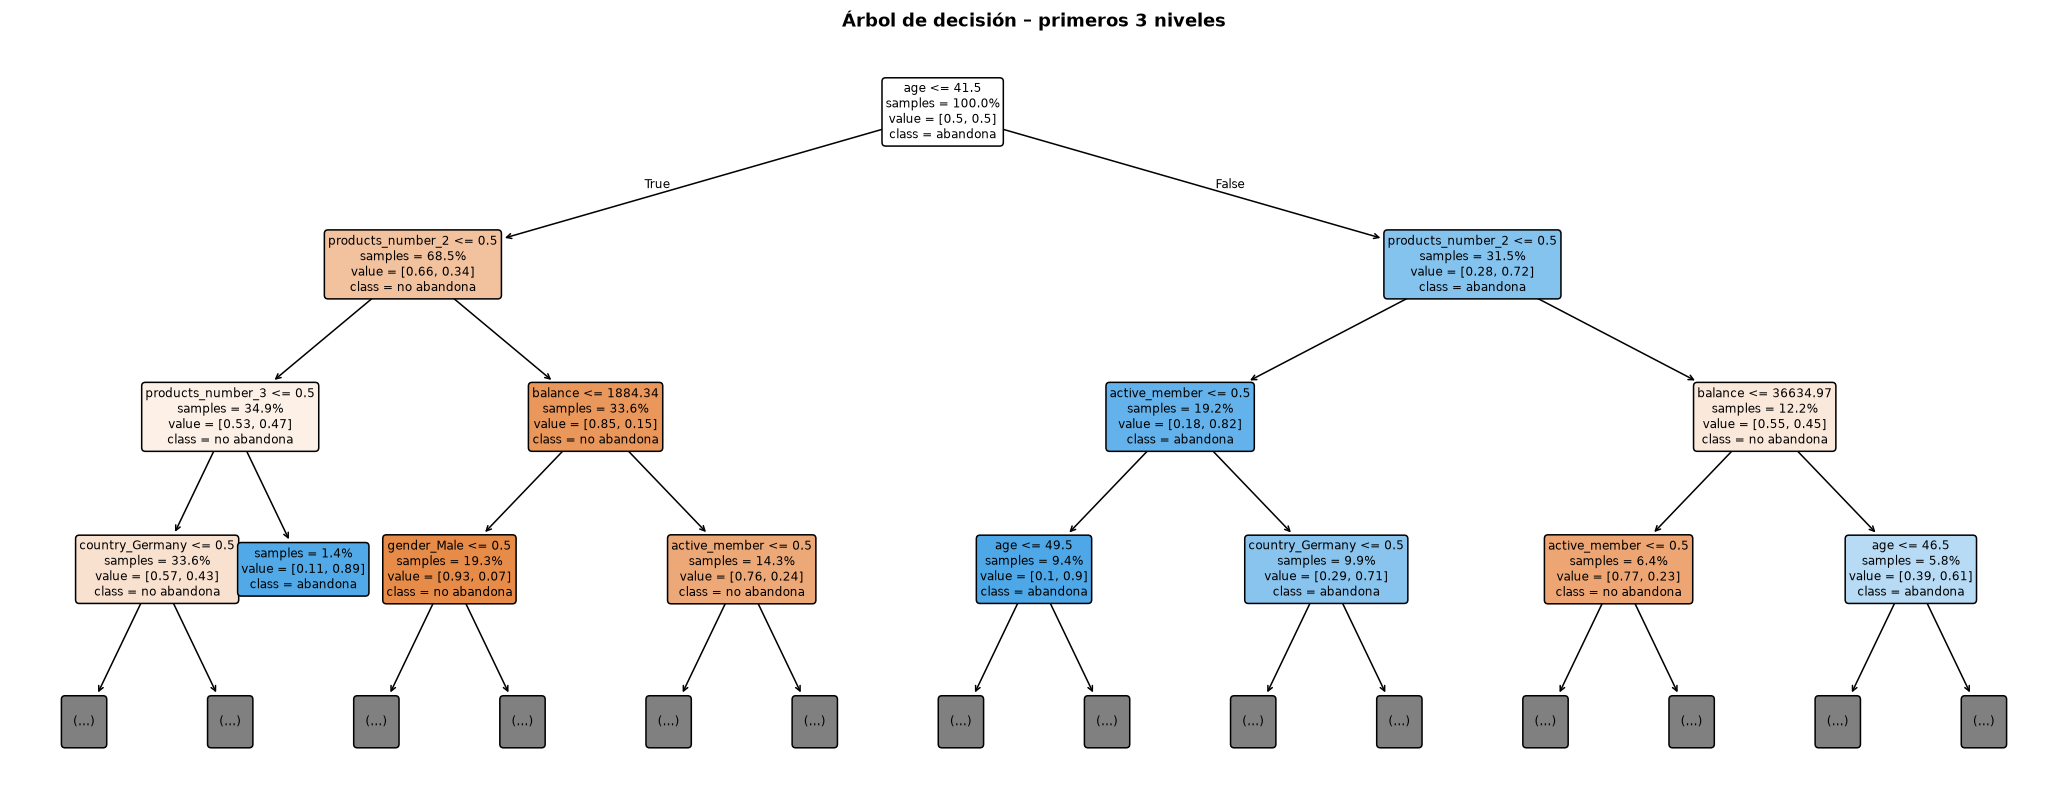

In [26]:
pre_dt, m_dt = dt.named_steps["pre"], dt.named_steps["modelo"]
nombres_dt = pre_dt.get_feature_names_out()
fig, ax = plt.subplots(figsize=(24, 9))
plot_tree(m_dt, feature_names=nombres_dt, class_names=["no abandona", "abandona"], max_depth=3, filled=True,
          rounded=True, impurity=False, proportion=True, precision=2, fontsize=8, ax=ax)
ax.set_title("Árbol de decisión – primeros 3 niveles", fontweight="bold")
plt.savefig(FIG_DIR / "02_arbol.png", bbox_inches="tight"); plt.show()

In [27]:
# Reglas de las hojas, ordenadas por riesgo (tasa REAL de abandono en entrenamiento, sin ponderar)
Xt_train = pd.DataFrame(pre_dt.transform(X_train), columns=nombres_dt, index=X_train.index)
hoja = m_dt.apply(Xt_train.values)
reglas_txt = {}
arbol = m_dt.tree_
def camino(m):
    # reconstruye la regla de cada hoja recorriendo el árbol desde la raíz
    rutas = {}
    def rec(n, cond):
        if arbol.children_left[n] == -1:
            rutas[n] = cond; return
        f, t = nombres_dt[arbol.feature[n]], arbol.threshold[n]
        fmt = (lambda v: f"{v:,.0f}") if f in ("balance", "credit_score", "age") else (lambda v: f"{v:.1f}")
        if f.startswith(("country_", "gender_", "products_number_")):
            var, val = f.rsplit("_", 1)
            rec(arbol.children_left[n], cond + [f"{var} ≠ {val}"]); rec(arbol.children_right[n], cond + [f"{var} = {val}"])
        elif f == "active_member":
            rec(arbol.children_left[n], cond + ["inactivo"]); rec(arbol.children_right[n], cond + ["activo"])
        else:
            rec(arbol.children_left[n], cond + [f"{f} ≤ {fmt(t)}"]); rec(arbol.children_right[n], cond + [f"{f} > {fmt(t)}"])
    rec(0, [])
    return rutas
rutas = camino(m_dt)
hojas = (pd.DataFrame({"hoja": hoja, "churn": y_train.values}).groupby("hoja")["churn"].agg(["size", "mean"])
         .rename(columns={"size": "clientes (train)", "mean": "tasa real de abandono"}))
hojas["regla"] = [" Y ".join(rutas[h]) for h in hojas.index]
hojas["predicción"] = [("abandona" if m_dt.tree_.value[h][0][1] > m_dt.tree_.value[h][0][0] else "no abandona") for h in hojas.index]
hojas = hojas.sort_values("tasa real de abandono", ascending=False)
pd.set_option("display.max_colwidth", 200)
print("Hojas de MAYOR riesgo:"); display(hojas.head(6))
print("Hojas de MENOR riesgo:"); display(hojas.tail(4))

Hojas de MAYOR riesgo:


,clientes (train),tasa real de abandono,regla,predicción
hoja,,,,
33,52,0.9808,"age > 42 Y products_number ≠ 2 Y inactivo Y age > 50 Y balance ≤ 24,557",abandona
34,158,0.8544,"age > 42 Y products_number ≠ 2 Y inactivo Y age > 50 Y balance > 24,557",abandona
30,177,0.7062,age > 42 Y products_number ≠ 2 Y inactivo Y age ≤ 50 Y gender ≠ Male,abandona
10,82,0.6829,age ≤ 42 Y products_number ≠ 2 Y products_number = 3,abandona
40,111,0.6486,age > 42 Y products_number ≠ 2 Y activo Y country = Germany Y age ≤ 54,abandona
55,69,0.6232,"age > 42 Y products_number = 2 Y balance > 36,635 Y age > 46 Y inactivo",abandona


Hojas de MENOR riesgo:


,clientes (train),tasa real de abandono,regla,predicción
hoja,,,,
24,130,0.0077,"age ≤ 42 Y products_number = 2 Y balance > 1,884 Y activo Y credit_score ≤ 608",no abandona
18,333,0.0000,"age ≤ 42 Y products_number = 2 Y balance ≤ 1,884 Y gender = Male Y activo",no abandona
14,137,0.0000,"age ≤ 42 Y products_number = 2 Y balance ≤ 1,884 Y gender ≠ Male Y credit_score ≤ 584",no abandona
49,104,0.0000,"age > 42 Y products_number = 2 Y balance ≤ 36,635 Y activo Y age > 54",no abandona


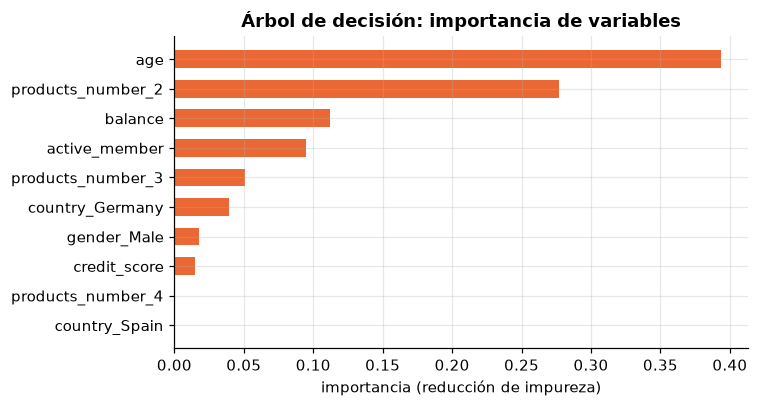

In [28]:
imp_dt = pd.Series(m_dt.feature_importances_, index=nombres_dt).sort_values()
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.barh(imp_dt.index, imp_dt.values, color=C_DT, height=0.6)
ax.set(xlabel="importancia (reducción de impureza)", title="Árbol de decisión: importancia de variables")
plt.tight_layout(); plt.savefig(FIG_DIR / "02_importancia_arbol.png", bbox_inches="tight"); plt.show()

**Interpretación del árbol**

- **La primera división es la edad (≤ 41,5 años)**, y en ambas ramas la segunda es **si el cliente tiene exactamente 2 productos**. El árbol llega a las mismas dos variables dominantes que la regresión logística, pero por otro camino.
- **Segmentos de mayor riesgo** (reglas legibles para el negocio):
  - *Mayores de 50, sin 2 productos e inactivos* → **85–98 %** de abandono real.
  - *Mujeres de 42 a 50 años, sin 2 productos e inactivas* → **71 %**.
  - *Menores de 42 con 3 productos* → **68 %**.
  - *Activos de 42 a 54 años en Alemania, sin 2 productos* → **65 %**.
- **Segmentos de menor riesgo:** varias hojas de *menores de 42 años con 2 productos* (activos, o con saldo casi nulo) tienen **0–1 %** de abandono real (≈ 600 clientes de entrenamiento).
- **Importancia por reducción de impureza:** `age` y `products_number_2` dominan, seguidas de `active_member`. A diferencia de la RL, el árbol sí usa `balance`, pero solo en interacción: por ejemplo, separa a los clientes de 2 productos con saldo casi nulo (muy bajo riesgo) de los que tienen saldo, o divide a los mayores de 50 inactivos según su saldo.
- **Limitación:** el árbol produce riesgos "escalonados" (29 valores posibles, uno por hoja), mientras que la RL ordena a los clientes de forma continua. Esto explica en parte su menor AP.

### 8.3 Importancia por permutación (validación)

Mide cuánto **empeora el AP** en validación cuando se desordenan al azar los valores de una variable (se rompe su relación con el abandono). Es agnóstica al modelo y se calcula sobre las **variables originales**, así que compara los dos modelos en la misma escala. `age` incluye el efecto de `age_sq`, porque al permutarla se recalculan ambas.

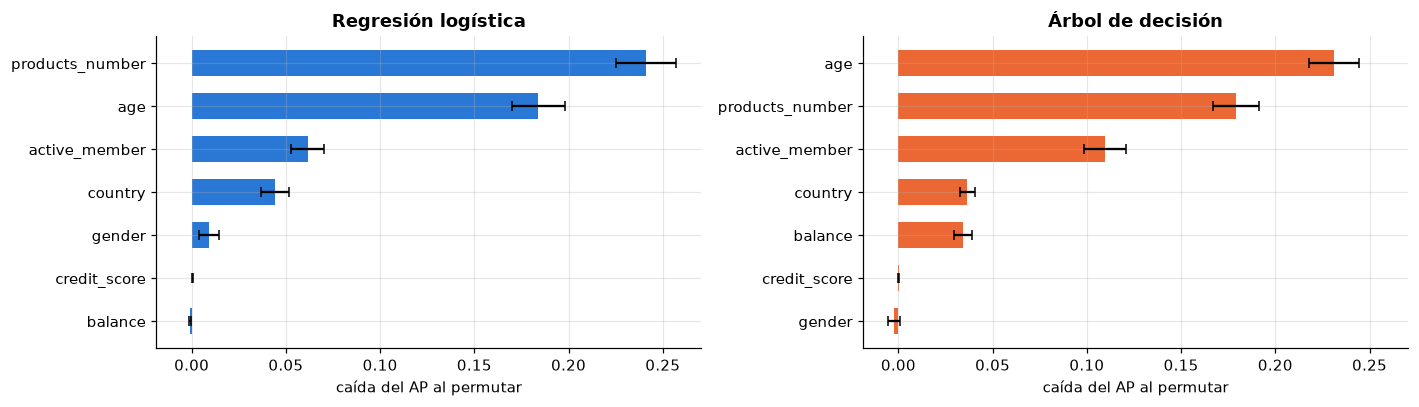

,Regresión logística,Árbol de decisión
products_number,0.2410,0.1790
age,0.1840,0.2310
active_member,0.0620,0.1100
country,0.0440,0.0370
gender,0.0090,-0.0020
credit_score,0.0000,0.0000
balance,-0.0010,0.0340


In [29]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8), sharex=True)
perm = {}
for ax, (nombre, m) in zip(axes, MODELOS.items()):
    r = permutation_importance(m, X_val, y_val, scoring="average_precision", n_repeats=20, random_state=SEED, n_jobs=-1)
    s = pd.DataFrame({"media": r.importances_mean, "de": r.importances_std}, index=FEATURES).sort_values("media")
    perm[nombre] = s["media"]
    ax.barh(s.index, s["media"], xerr=s["de"], color=COLORES[nombre], height=0.6, capsize=3)
    ax.set(title=nombre, xlabel="caída del AP al permutar")
plt.tight_layout(); plt.savefig(FIG_DIR / "02_importancia_permutacion.png", bbox_inches="tight"); plt.show()
pd.DataFrame(perm).sort_values("Regresión logística", ascending=False).round(3)

### 8.4 Valores SHAP: resumen global

Los valores SHAP reparten la predicción de cada cliente entre sus variables: **valor base + Σ SHAP = predicción** del modelo. Para la regresión logística se calculan en escala log-odds (`LinearExplainer`) y para el árbol en escala de probabilidad (`TreeExplainer`). En el gráfico de enjambre (*beeswarm*), cada punto es un cliente de validación: la posición horizontal indica cuánto sube (derecha) o baja (izquierda) su riesgo esa variable, y el color indica si el valor de la variable es alto (rojo) o bajo (azul).

Background dataset has 6000 samples but max_samples=1000. Subsampling to 1000 samples for SHAP value computation. To use all samples, set max_samples=6000 when initializing the masker.


Sin combinar, |SHAP| medio: age = 2.29, age_sq = 1.59; combinado = 0.74


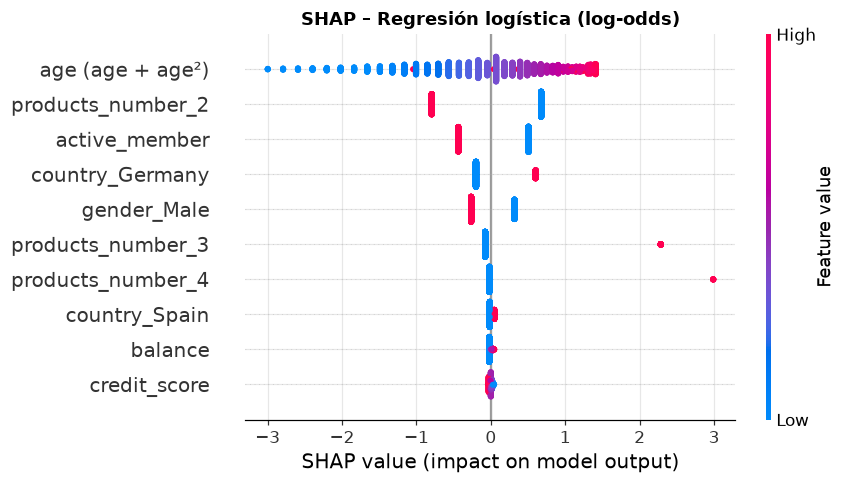

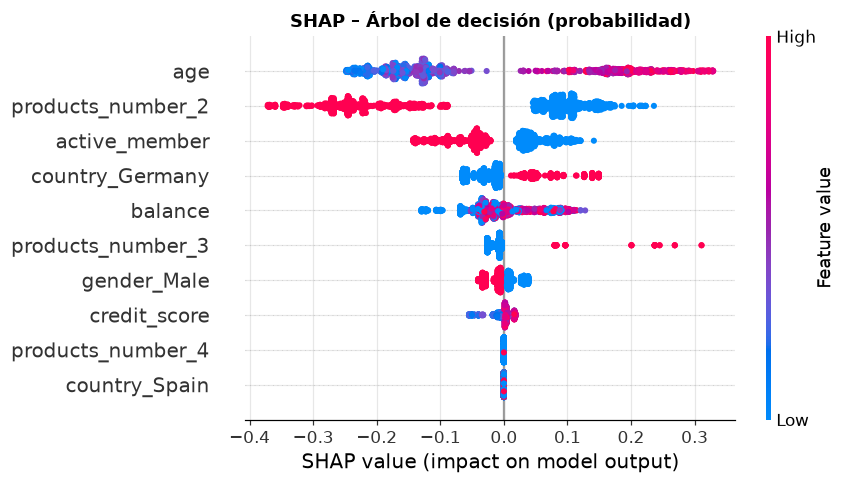

In [30]:
Xt_tr_lr = pd.DataFrame(pre_lr.transform(X_train), columns=nombres_lr)
Xt_va_lr = pd.DataFrame(pre_lr.transform(X_val), columns=nombres_lr, index=X_val.index)
Xt_va_dt = pd.DataFrame(pre_dt.transform(X_val), columns=nombres_dt, index=X_val.index)

expl_lr = shap.LinearExplainer(m_lr, shap.maskers.Independent(Xt_tr_lr, max_samples=1000))
sv_lr = expl_lr(Xt_va_lr)
expl_dt = shap.TreeExplainer(m_dt)
sv_dt = expl_dt(Xt_va_dt)[:, :, 1]          # contribuciones a P(abandona)

# age y age_sq están muy correlacionadas: sus SHAP por separado son grandes y opuestos (±15) y no se pueden leer.
# Se suman en un único efecto "age (age + age²)" y se colorea con la edad real del cliente.
i_age, i_sq = list(nombres_lr).index("age"), list(nombres_lr).index("age_sq")
cols = [i for i in range(len(nombres_lr)) if i != i_sq]
vals = sv_lr.values.copy(); vals[:, i_age] += vals[:, i_sq]
datos = Xt_va_lr.values.copy(); datos[:, i_age] = X_val["age"].fillna(X_train["age"].median()).values
sv_lr_comb = shap.Explanation(vals[:, cols], sv_lr.base_values, data=datos[:, cols],
                              feature_names=[("age (age + age²)" if n == "age" else n) for n in np.array(nombres_lr)[cols]])
print(f"Sin combinar, |SHAP| medio: age = {np.abs(sv_lr.values[:, i_age]).mean():.2f}, age_sq = {np.abs(sv_lr.values[:, i_sq]).mean():.2f}; "
      f"combinado = {np.abs(vals[:, i_age]).mean():.2f}")

plt.figure()
shap.plots.beeswarm(sv_lr_comb, max_display=12, show=False, plot_size=(8, 4.5))
plt.title("SHAP – Regresión logística (log-odds)", fontweight="bold")
plt.tight_layout(); plt.savefig(FIG_DIR / "02_shap_lr.png", bbox_inches="tight"); plt.show()

plt.figure()
shap.plots.beeswarm(sv_dt, max_display=12, show=False, plot_size=(8, 4.5))
plt.title("SHAP – Árbol de decisión (probabilidad)", fontweight="bold")
plt.tight_layout(); plt.savefig(FIG_DIR / "02_shap_dt.png", bbox_inches="tight"); plt.show()

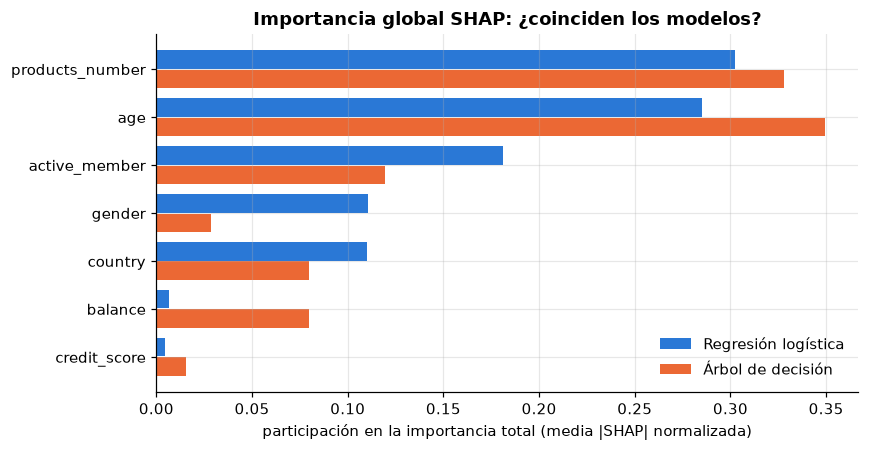

,RL (log-odds),Árbol (prob.)
products_number,30.3%,32.8%
age,28.5%,34.9%
active_member,18.1%,12.0%
gender,11.0%,2.9%
country,11.0%,8.0%
balance,0.7%,8.0%
credit_score,0.4%,1.5%


In [31]:
def por_variable_original(valores, nombres):
    """Suma las contribuciones SHAP de las columnas transformadas que vienen de la misma variable original
    (age + age_sq -> age; country_Germany + country_Spain -> country; products_number_2/3/4 -> products_number)."""
    d = pd.DataFrame(valores, columns=nombres)
    grupo = {n: next((f for f in FEATURES if n == f or n.startswith(f + "_")), n) for n in nombres}
    grupo["age_sq"] = "age"
    return d.T.groupby(pd.Series(grupo)).sum().T[[f for f in FEATURES]]

imp_shap = pd.DataFrame({"RL (log-odds)": por_variable_original(sv_lr.values, nombres_lr).abs().mean(),
                         "Árbol (prob.)": por_variable_original(sv_dt.values, nombres_dt).abs().mean()})
imp_shap_rel = imp_shap / imp_shap.sum()
imp_shap_rel = imp_shap_rel.sort_values("RL (log-odds)")
fig, ax = plt.subplots(figsize=(8, 4.2))
y_ = np.arange(len(imp_shap_rel))
ax.barh(y_ + 0.2, imp_shap_rel["RL (log-odds)"], 0.38, color=C_LR, label="Regresión logística")
ax.barh(y_ - 0.2, imp_shap_rel["Árbol (prob.)"], 0.38, color=C_DT, label="Árbol de decisión")
ax.set_yticks(y_, imp_shap_rel.index); ax.legend(frameon=False, loc="lower right")
ax.set(xlabel="participación en la importancia total (media |SHAP| normalizada)", title="Importancia global SHAP: ¿coinciden los modelos?")
plt.tight_layout(); plt.savefig(FIG_DIR / "02_shap_comparacion.png", bbox_inches="tight"); plt.show()
imp_shap_rel.sort_values("RL (log-odds)", ascending=False).style.format("{:.1%}")

**Interpretación SHAP global**

- **Los dos modelos coinciden en las tres variables principales**: `products_number`, `age` y `active_member` explican entre el 77 % (RL) y el 80 % (árbol) de la importancia total. Que dos modelos de naturaleza tan distinta lleguen a la misma jerarquía indica que estos patrones son **robustos** y no un artefacto de un modelo.
- **En el *beeswarm* de la RL**, `age` (combinando `age` y `age²`) tiene la mayor dispersión: los clientes jóvenes (azul) quedan todos a la izquierda (menos riesgo) y los de mediana edad (morado-rojo) a la derecha. Los mayores de 70 (rojo intenso) vuelven hacia el centro por el término cuadrático. `products_number` = 2 aparece como un bloque compacto a la izquierda (protección), y 3–4 productos como unos pocos puntos muy a la derecha: son clientes escasos pero con efecto enorme.
- **Diferencias entre modelos:**
  - **`gender`** pesa más en la RL (11 %) que en el árbol (3 %). La RL suma el efecto del género a todos los clientes por igual, mientras que el árbol solo lo usa en una rama (mujeres de 42–50 años inactivas).
  - **`balance`** pesa 8 % en el árbol y ≈ 0 % en la RL: el árbol lo aprovecha en interacciones que la RL, siendo aditiva, no puede capturar.
- **La importancia por permutación lo confirma**: desordenar `products_number` hace caer el AP en ≈ 0,25 (RL) y desordenar `age` en ≈ 0,18. Desordenar `credit_score` o `balance` no cambia nada en la RL.

### 8.5 Gráficos ICE y dependencia parcial (PDP)

Cada línea delgada (**ICE**) muestra cómo cambiaría el riesgo de **un cliente** si solo se moviera una variable. La línea gruesa (**PDP**) es el promedio. Si las líneas ICE son paralelas, el efecto es igual para todos. Si se cruzan o se separan, hay **interacciones**: el efecto de la variable depende de las demás.

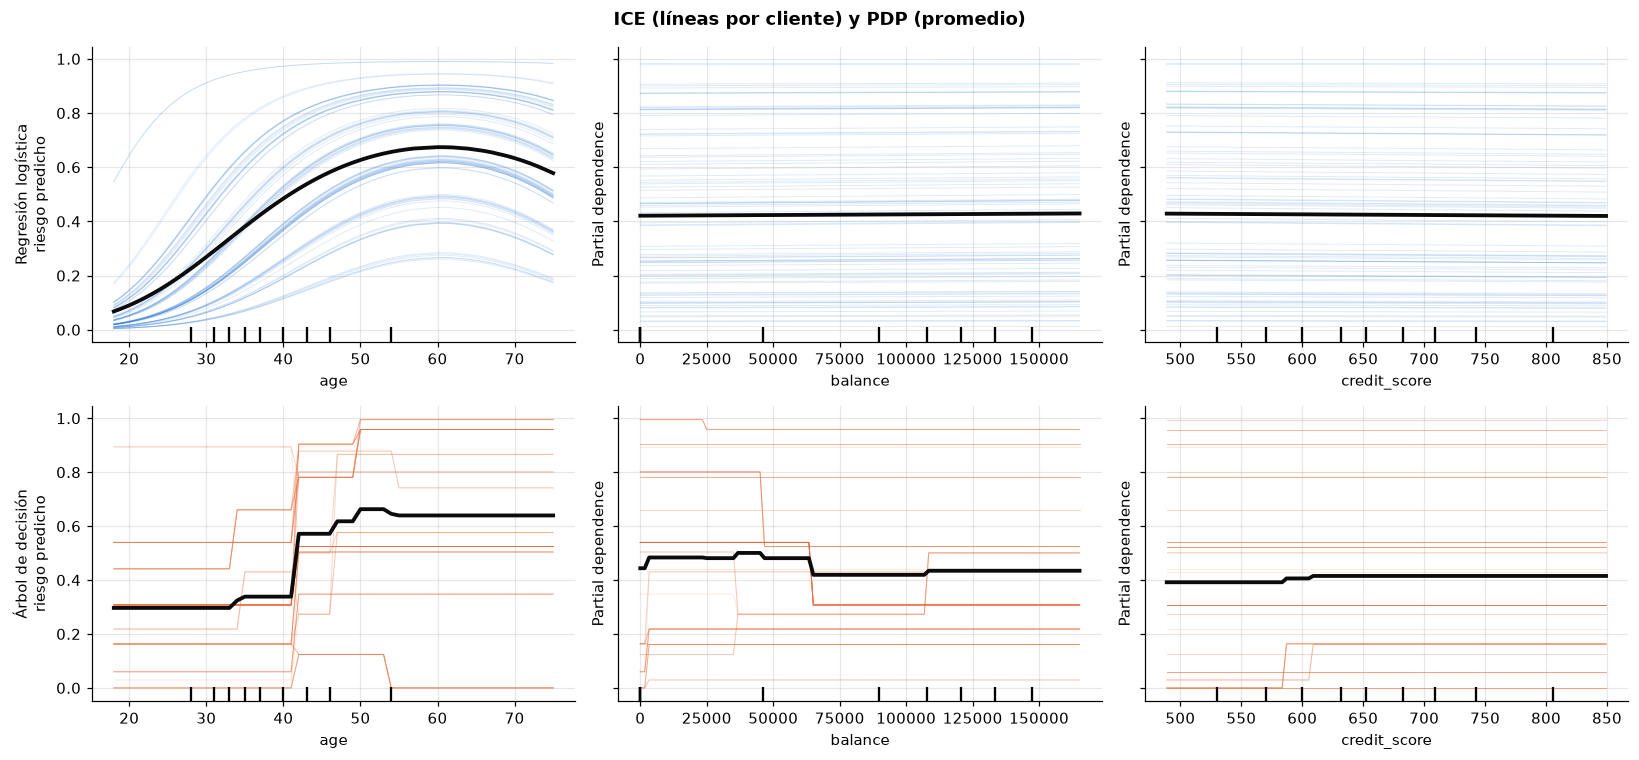

In [32]:
muestra = X_val.sample(300, random_state=SEED)
vars_ice = ["age", "balance", "credit_score"]
fig, axes = plt.subplots(2, 3, figsize=(15, 7), sharey="row")
for i, (nombre, m) in enumerate(MODELOS.items()):
    PartialDependenceDisplay.from_estimator(
        m, muestra, vars_ice, kind="both", centered=False, subsample=80, random_state=SEED, ax=axes[i],
        ice_lines_kw={"color": COLORES[nombre], "alpha": 0.15, "lw": 0.6},
        pd_line_kw={"color": "#0b0b0b", "lw": 2.5, "ls": "-"})
    axes[i][0].set_ylabel(f"{nombre}\nriesgo predicho")
for ax in axes.ravel():
    if ax.get_legend(): ax.get_legend().remove()
fig.suptitle("ICE (líneas por cliente) y PDP (promedio)", fontweight="bold")
plt.tight_layout(); plt.savefig(FIG_DIR / "02_ice_pdp.png", bbox_inches="tight"); plt.show()

**Interpretación ICE / PDP**

- **`age` en la RL:** todas las curvas ICE tienen la misma forma de campana con el máximo cerca de 60 años, pero **no son paralelas** en escala de probabilidad. Para clientes de bajo riesgo de base (2 productos, activos) la curva casi no se mueve, mientras que para clientes de riesgo medio la edad lleva el riesgo de 0,1 a 0,9. Aunque el modelo es aditivo en log-odds, la función logística hace que **la edad importe mucho más para quien ya tiene otros factores de riesgo**.
- **`age` en el árbol:** el efecto es escalonado, con saltos en 33, 41–42 y 46–50 años (las particiones del árbol). La PDP sube de ≈ 0,28 a ≈ 0,66, el mismo orden de magnitud que la RL. Algunas curvas ICE no cambian en absoluto: son clientes que caen en ramas donde la edad ya no se vuelve a usar (por ejemplo, 3 productos).
- **`balance` y `credit_score`:** en la RL las líneas son planas (sin efecto). En el árbol, `balance` produce saltos en algunos clientes (alrededor de 2.000, 37.000 y 65.000) y en otros no, lo que confirma que el árbol lo usa **solo en interacción** con otras variables.

## 9. Comportamiento local: muestra de predicciones individuales

Se eligen **cinco clientes del conjunto de prueba**. Los cuatro primeros corresponden a cada casilla de la matriz de confusión del modelo elegido (regresión logística, umbral 0,5): el verdadero positivo con mayor riesgo, el falso positivo con mayor riesgo, el falso negativo con menor riesgo y el verdadero negativo con menor riesgo. El quinto es el **caso frontera**, el cliente con riesgo más cercano a 0,5, donde la decisión de contactar o no es más incierta. Así se ven los aciertos y también **por qué se equivoca** el modelo.

In [33]:
p_lr_te, p_dt_te = lr.predict_proba(X_test)[:, 1], dt.predict_proba(X_test)[:, 1]
res = X_test.assign(churn=y_test, p_lr=p_lr_te, p_dt=p_dt_te, pred=(p_lr_te >= 0.5).astype(int))
casos = {
    "A · Verdadero positivo": res[(res.churn == 1) & (res.pred == 1)].p_lr.idxmax(),
    "B · Falso positivo": res[(res.churn == 0) & (res.pred == 1)].p_lr.idxmax(),
    "C · Falso negativo": res[(res.churn == 1) & (res.pred == 0)].p_lr.idxmin(),
    "D · Verdadero negativo": res[(res.churn == 0) & (res.pred == 0)].p_lr.idxmin(),
    "E · Caso frontera": (res.p_lr - 0.5).abs().idxmin(),
}
tabla_casos = res.loc[list(casos.values())].copy()
tabla_casos.index = list(casos.keys())
tabla_casos.style.format({"credit_score": "{:.0f}", "balance": "{:,.0f}", "age": "{:.0f}", "p_lr": "{:.3f}", "p_dt": "{:.3f}"})

,credit_score,balance,age,country,gender,products_number,active_member,churn,p_lr,p_dt,pred
A · Verdadero positivo,819,"120,657",49,Germany,Female,4,0,1,0.996,0.904,1
B · Falso positivo,718,0,67,France,Female,3,1,0,0.964,0.801,1
C · Falso negativo,596,"210,433",21,France,Male,2,1,1,0.009,0.029,0
D · Verdadero negativo,738,0,18,France,Male,2,1,0,0.004,0.000,0
E · Caso frontera,700,0,32,France,Female,1,0,0,0.500,0.539,1


### 9.1 Explicación SHAP de cada caso (ambos modelos)

Las barras muestran cuánto empuja cada variable el riesgo hacia arriba (naranja) o hacia abajo (azul) frente al valor base del modelo. Las contribuciones de las columnas one-hot y de `age_sq` se suman en su variable original, así que hay una barra por variable.

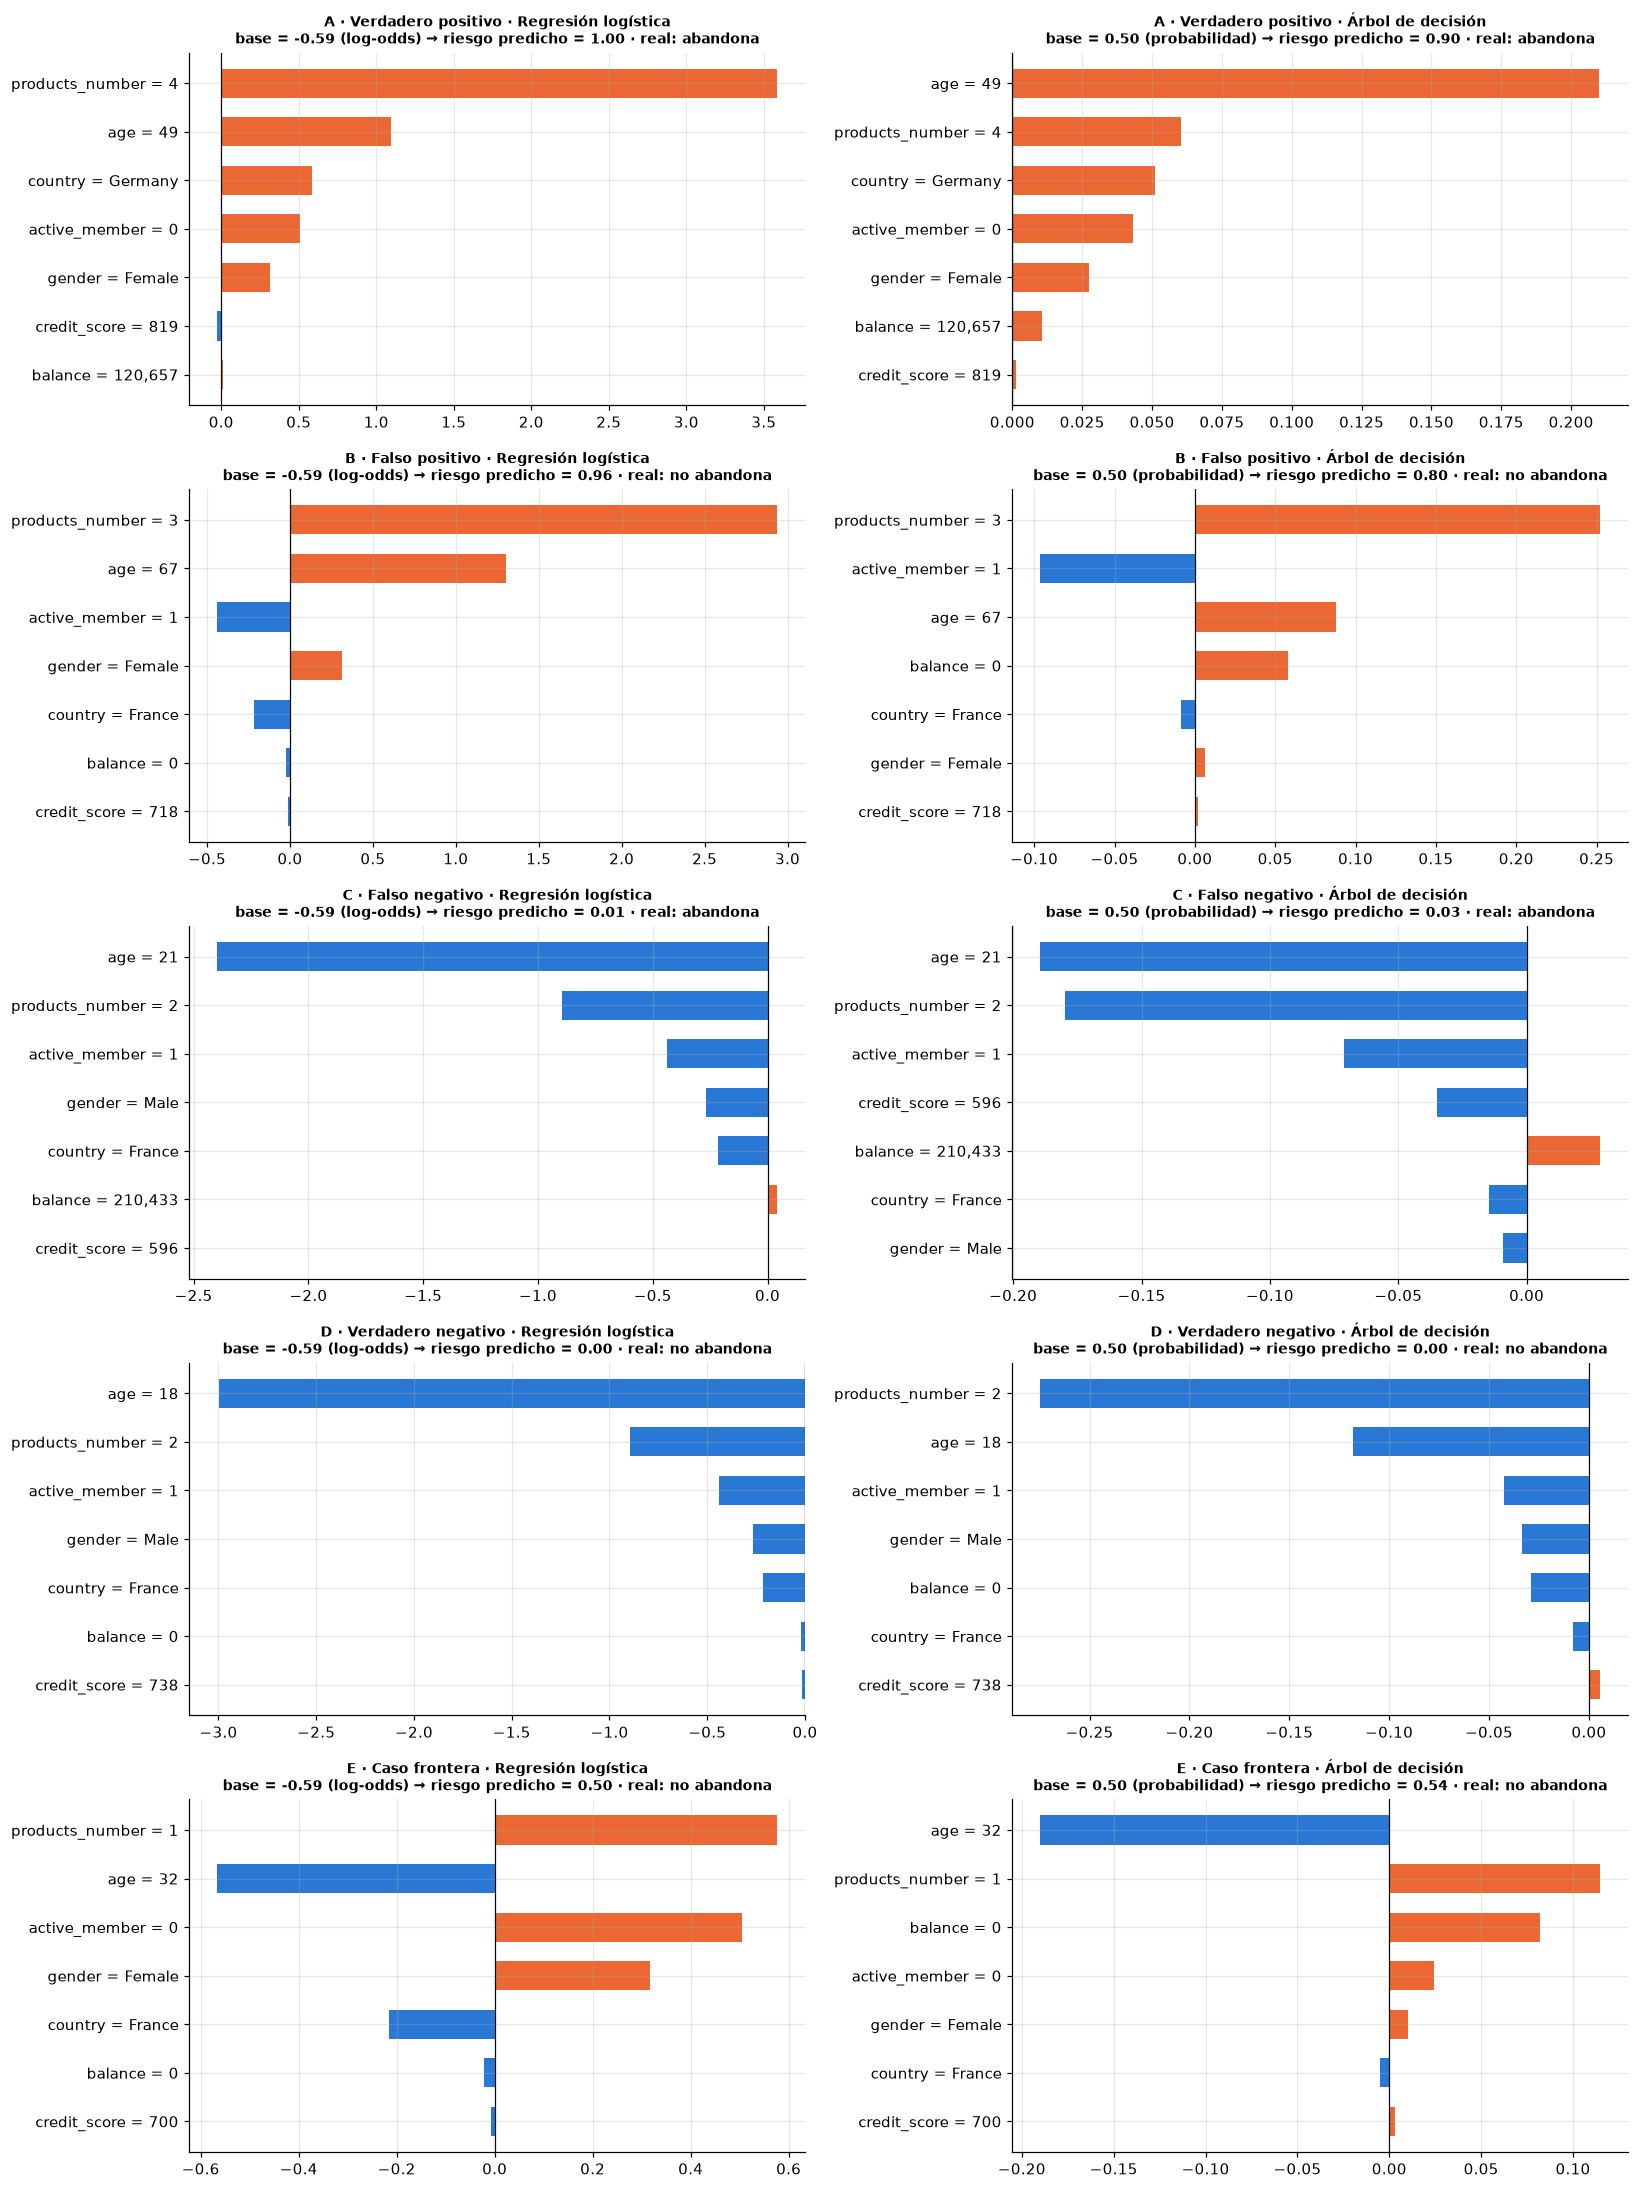

In [34]:
Xt_te_lr = pd.DataFrame(pre_lr.transform(X_test), columns=nombres_lr, index=X_test.index)
Xt_te_dt = pd.DataFrame(pre_dt.transform(X_test), columns=nombres_dt, index=X_test.index)
sv_te_lr = expl_lr(Xt_te_lr.loc[list(casos.values())])
sv_te_dt = expl_dt(Xt_te_dt.loc[list(casos.values())])[:, :, 1]

def etiqueta(n, fila):
    v = fila[n]
    if pd.isna(v): return f"{n} = (nulo, imputado)"
    if n == "balance": return f"balance = {v:,.0f}"
    if n in ("age", "credit_score", "active_member", "products_number"): return f"{n} = {v:.0f}"
    return f"{n} = {v}"

fig, axes = plt.subplots(len(casos), 2, figsize=(15, 4 * len(casos)))
for i, (caso, idx) in enumerate(casos.items()):
    fila = X_test.loc[idx]
    for j, (nombre, sv, nombres) in enumerate([("Regresión logística", sv_te_lr, nombres_lr), ("Árbol de decisión", sv_te_dt, nombres_dt)]):
        s = por_variable_original(sv.values[[i]], nombres).iloc[0]     # una barra por variable original
        s = s.reindex(s.abs().sort_values().index)
        ax = axes[i, j]
        ax.barh([etiqueta(n, fila) for n in s.index], s.values, color=[C_SI if v > 0 else C_NO for v in s.values], height=0.6)
        ax.axvline(0, color="#0b0b0b", lw=0.8)
        p = res.loc[idx, "p_lr" if j == 0 else "p_dt"]
        escala = "log-odds" if j == 0 else "probabilidad"
        ax.set_title(f"{caso} · {nombre}\nbase = {sv.base_values[i]:.2f} ({escala}) → riesgo predicho = {p:.2f} · real: {'abandona' if res.loc[idx, 'churn'] else 'no abandona'}", fontsize=9)
plt.tight_layout(); plt.savefig(FIG_DIR / "02_shap_casos.png", bbox_inches="tight"); plt.show()

### 9.2 Explicación LIME (regresión logística)

LIME ajusta un modelo lineal **local** alrededor de cada cliente: genera clientes "vecinos" perturbados, los puntúa con el modelo y ve qué variables explican mejor las diferencias. Trabaja sobre las **variables originales** y presenta las numéricas como intervalos (por ejemplo `age > 44`), lo que facilita explicar el resultado a un asesor comercial. La función de predicción recibe la matriz codificada de LIME, la convierte al formato original y llama al *pipeline* completo.

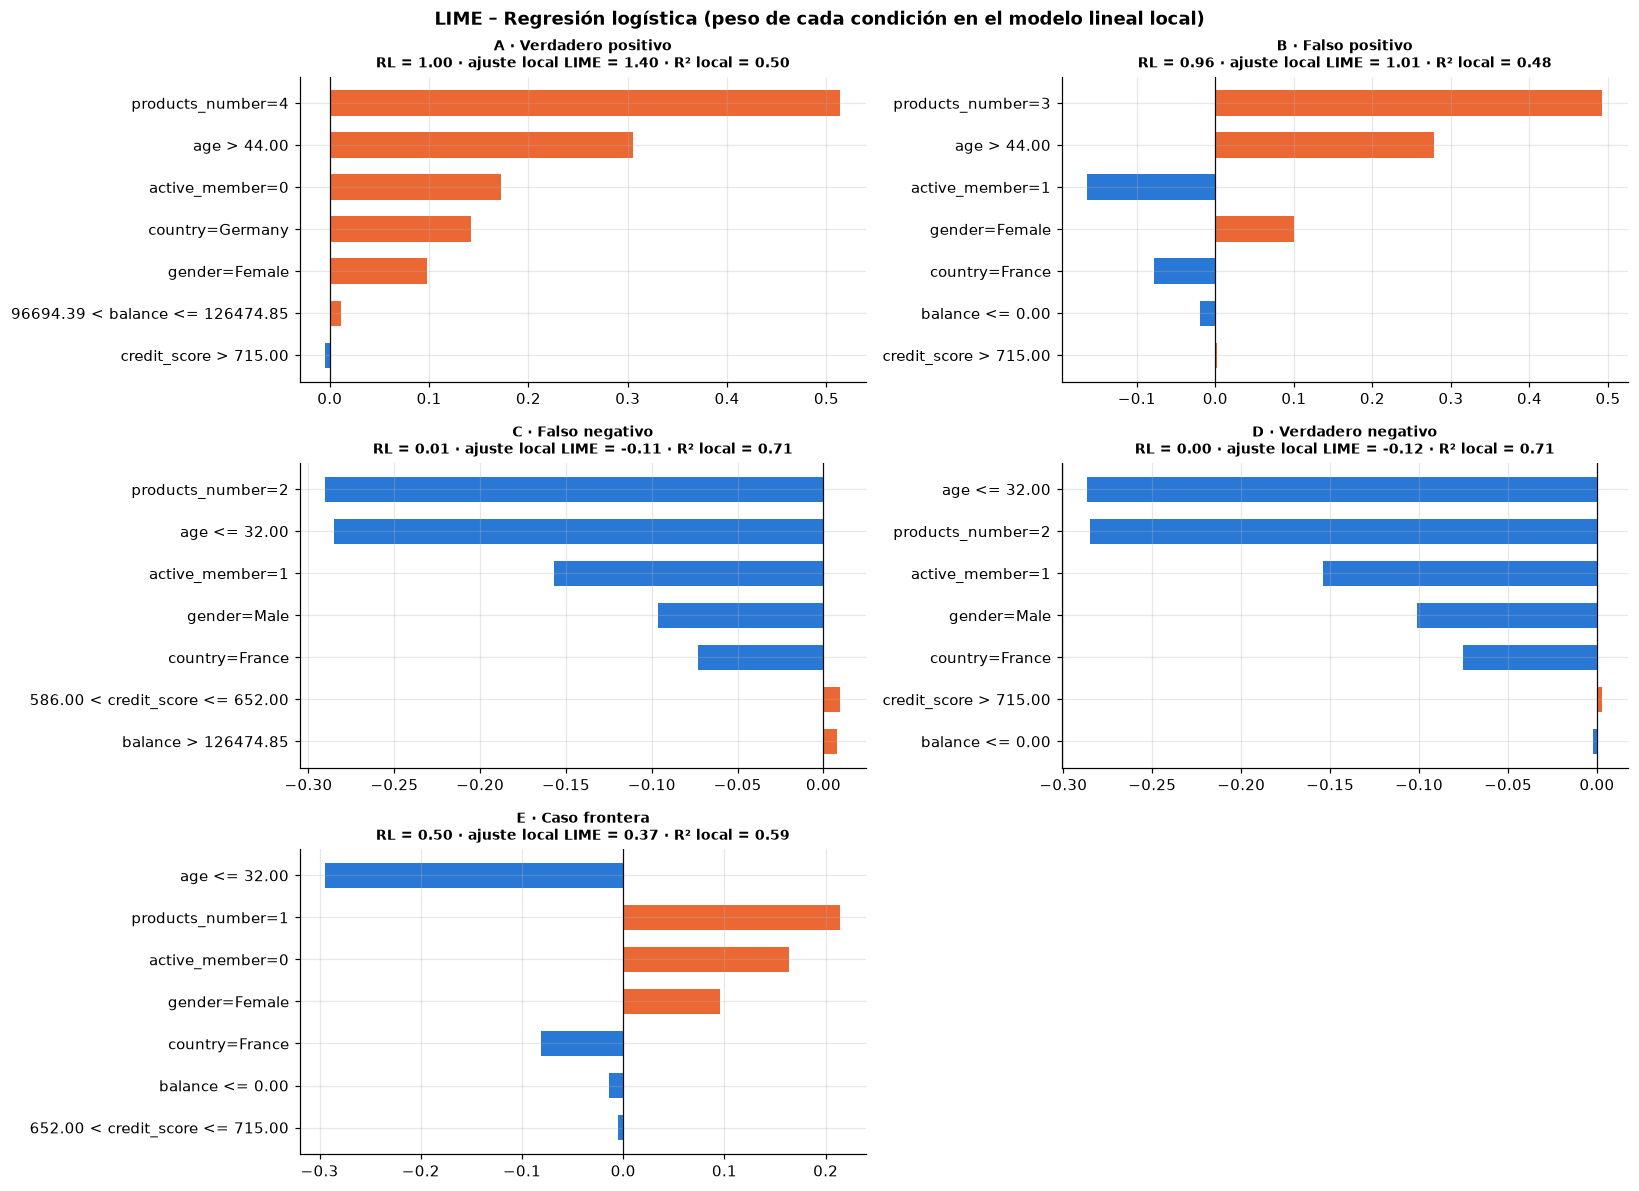

In [35]:
CAT_LIME = ["country", "gender", "products_number", "active_member"]
NUM_LIME = ["credit_score", "balance", "age"]
ORDEN_LIME = NUM_LIME + CAT_LIME
medianas = X_train[NUM_LIME].median()
categorias = {c: sorted(X_train[c].dropna().unique().tolist()) for c in CAT_LIME}

def a_lime(X):
    """DataFrame original -> matriz numérica para LIME (categóricas como códigos, nulos imputados)."""
    Z = X[ORDEN_LIME].copy()
    Z[NUM_LIME] = Z[NUM_LIME].fillna(medianas)
    for c in CAT_LIME: Z[c] = Z[c].map({v: k for k, v in enumerate(categorias[c])})
    return Z.values.astype(float)

def predict_fn_factory(modelo):
    def predict_fn(Z):
        X = pd.DataFrame(Z, columns=ORDEN_LIME)
        for c in CAT_LIME: X[c] = [categorias[c][int(round(k))] for k in X[c]]
        return modelo.predict_proba(X[FEATURES])
    return predict_fn

lime_expl = LimeTabularExplainer(
    a_lime(X_train), feature_names=ORDEN_LIME, class_names=["no abandona", "abandona"], mode="classification",
    categorical_features=[ORDEN_LIME.index(c) for c in CAT_LIME],
    categorical_names={ORDEN_LIME.index(c): [str(v) for v in categorias[c]] for c in CAT_LIME},
    discretize_continuous=True, random_state=SEED)

fig, axes = plt.subplots(3, 2, figsize=(15, 11))
axes.ravel()[-1].axis("off")
lime_res = {}
for ax, (caso, idx) in zip(axes.ravel(), casos.items()):
    e = lime_expl.explain_instance(a_lime(X_test.loc[[idx]])[0], predict_fn_factory(lr), num_features=7, num_samples=5000)
    lst = e.as_list()[::-1]
    lime_res[caso] = e.as_list()
    ax.barh([k for k, _ in lst], [v for _, v in lst], color=[C_SI if v > 0 else C_NO for _, v in lst], height=0.6)
    ax.axvline(0, color="#0b0b0b", lw=0.8)
    ax.set_title(f"{caso}\nRL = {res.loc[idx, 'p_lr']:.2f} · ajuste local LIME = {e.local_pred[0]:.2f} · R² local = {e.score:.2f}", fontsize=9)
fig.suptitle("LIME – Regresión logística (peso de cada condición en el modelo lineal local)", fontweight="bold")
plt.tight_layout(); plt.savefig(FIG_DIR / "02_lime_casos.png", bbox_inches="tight"); plt.show()

**Interpretación de los casos individuales**

| Caso | Perfil | RL / Árbol | ¿Qué explica la predicción? |
|---|---|---|---|
| **A · Verdadero positivo** | Mujer, 49 años, Alemania, **4 productos**, inactiva | 1,00 / 0,90 · **abandonó** | Todos los factores empujan hacia arriba: 4 productos (la mayor contribución en la RL: +3,6 log-odds), edad cercana al pico de riesgo, Alemania, inactividad y género. Es el perfil "de libro" que el modelo detecta sin dificultad. |
| **B · Falso positivo** | Mujer, 67 años, Francia, **3 productos**, activa, saldo 0 | 0,96 / 0,80 · no abandonó | **`products_number = 3` domina** (+3,0 log-odds en la RL): el 83 % de los clientes con 3 productos abandona y el modelo aplica esa regla. Ser activa y francesa reduce el riesgo, pero no lo suficiente. Ella pertenece al 17 % que se queda: con estas variables, el modelo **no tiene cómo distinguirla**. Para el banco es un error barato (un contacto de más a una clienta que sí estaba en un grupo de alto riesgo). |
| **C · Falso negativo** | Hombre, **21 años**, Francia, **2 productos**, activo, saldo 210.433 | 0,01 / 0,03 · **abandonó** | Es el perfil de **menor riesgo** en casi todas las dimensiones: joven, 2 productos, activo, hombre, Francia. Solo el saldo alto empuja levemente hacia arriba (en el árbol). Su salida probablemente se debe a algo que **no está en los datos** (mudanza, oferta de un competidor, un evento de vida). Es un error **irreducible** con estas variables y muestra la necesidad de datos de comportamiento (transacciones, quejas, uso de canales). |
| **D · Verdadero negativo** | Hombre, 18 años, Francia, 2 productos, activo | 0,00 / 0,00 · no abandonó | Espejo del caso C: la misma combinación protectora. Los dos modelos le asignan riesgo prácticamente nulo y aciertan. |
| **E · Caso frontera** | Mujer, 32 años, Francia, **1 producto**, **inactiva**, saldo 0 | 0,50 / 0,54 · no abandonó | Fuerzas que se compensan: la **juventud** reduce el riesgo, mientras que tener **1 solo producto**, ser **inactiva** y mujer lo aumentan. Ambos modelos quedan en la frontera. Aquí la decisión de contactar depende del **umbral económico** (análisis de valor de negocio), no del modelo. |

**SHAP frente a LIME.** Ambas técnicas coinciden en las variables que más pesan en cada caso (productos, edad, actividad), lo que da confianza en las explicaciones. Hay diferencias de método:

- Para la RL, **SHAP es exacto**: las contribuciones suman exactamente la predicción en log-odds.
- **LIME es una aproximación** con un modelo lineal local sobre la probabilidad. Su ajuste es moderado (R² local entre 0,48 y 0,71) y en los casos extremos su predicción local se sale del rango [0, 1] (1,40 en el caso A). Esto ocurre porque, cerca de 0 o 1, la función logística está saturada y un modelo lineal no la representa bien.
- La ventaja de LIME es su formato de **condiciones legibles** (`age > 44`, `products_number = 3`), útil para explicarle la alerta a un asesor comercial. La ventaja de SHAP es su consistencia matemática.

## 10. Síntesis: ¿cómo funciona el modelo?

**El modelo funciona como una "tarjeta de puntaje" de cuatro factores principales:**

1. **Número de productos.** Es el factor dominante y no es lineal. **2 productos protege** (≈ 8 % de abandono); 1 producto es riesgo medio (≈ 28 %); **3–4 productos es riesgo muy alto** (> 80 %).
2. **Edad.** El riesgo crece fuertemente desde los 35 años, llega al máximo **alrededor de los 50–60** y baja en los mayores de 70.
3. **Actividad.** Un cliente **inactivo** tiene ≈ 2,6 veces los *odds* de uno activo.
4. **País y género.** **Alemania** duplica los *odds* frente a Francia y España. Las **mujeres** tienen ≈ 1,8 veces los *odds* de los hombres.

`balance` y `credit_score` casi no influyen una vez que se conocen los factores anteriores. `tenure`, `estimated_salary` y `credit_card` se descartaron desde el análisis exploratorio por no mostrar relación.

**Fortalezas.** El comportamiento es **coherente con el análisis exploratorio** y con la intuición de negocio. Los dos modelos, muy distintos entre sí, coinciden en los factores principales. Las explicaciones individuales (SHAP y LIME) tienen sentido y se pueden comunicar.

**Debilidades.** El modelo depende de perfiles estáticos: (a) aplica la regla "3 productos → abandona" incluso a quienes se quedan (caso B), y (b) no puede detectar a clientes de perfil seguro que abandonan por razones ajenas a los datos (caso C). Por eso el recall es bajo en jóvenes y en clientes con 2 productos.

**Consideración ética.** El modelo usa **género y país**. En una campaña de retención, el uso es "positivo" (ofrecer un beneficio, no negar un servicio), pero conviene revisarlo con el área de cumplimiento. Una alternativa es entrenar sin `gender` y medir cuánto se pierde: según la importancia por permutación, el costo en AP sería pequeño (≈ 0,01).

**Implicaciones para el negocio (hipótesis por validar, porque el modelo muestra asociaciones, no causalidad):**

- **Clientes de 1 producto:** campañas de venta cruzada hacia un segundo producto. Los clientes con 2 productos son los más leales.
- **Clientes con 3–4 productos:** su abandono es anómalo. Hay que investigar si se debe a ventas forzadas, cobros o mala experiencia, y revisar sus PQRS.
- **Miembros inactivos:** campañas de reactivación (uso de app, beneficios por transaccionar).
- **Segmento de 45–60 años** y **clientes en Alemania** (en el caso colombiano, el equivalente sería la región o el canal con mayor abandono): priorizarlos en la campaña.

---
## Exportación para el análisis de valor de negocio

Se guardan las probabilidades de ambos modelos en entrenamiento, validación y prueba, para calcular la ganancia esperada y el umbral económico.

In [36]:
pred = pd.concat([
    pd.DataFrame({"id": Xc.index, "split": s, "churn": yc.values,
                  "p_lr": lr.predict_proba(Xc)[:, 1], "p_dt": dt.predict_proba(Xc)[:, 1]})
    for s, (Xc, yc) in {"train": (X_train, y_train), "val": (X_val, y_val), "test": (X_test, y_test)}.items()])
pred.to_csv(PROC_DIR / "predicciones.csv", index=False)
print("Predicciones guardadas:", pred.shape)

Predicciones guardadas: (10000, 5)
